# Lab Day 1 — Mạng nơ-ron và thí nghiệm huấn luyện (Forest CoverType)

**MSSV:** 2A202602798 · Track 4 · Day 1 · VinUniversity AICB 2026

**Cách chạy trên Google Colab**
1. *Runtime → Change runtime type → **T4 GPU***.
2. *Runtime → **Run all***. Ô đầu tiên tự `git clone` repo (lấy `data/`, `scripts/`, `templates/`), tạo `submission_2A202602798/code/` và chuyển vào đó; các ô `%%writefile` ghi code các module (`data.py`, `model.py`, ...) vào thư mục này; các ô sau chạy Part 0 → Part 4.
3. Ô cuối nén thư mục nộp thành `submission_2A202602798.zip` và tải về. Sau đó *File → Download → Download .ipynb* để lấy notebook **có output**, đặt vào `submission_2A202602798/code/lab.ipynb`.

Nếu Colab bị ngắt giữa chừng: chạy lại *Run all*. Với `RESUME = True`, các thí nghiệm đã có `results/<exp_id>.json` được nạp lại, không huấn luyện lại.

Đường dẫn (khi chạy từ `submission_2A202602798/code/`): dữ liệu ở `../../data`, kết quả ghi vào `../figures/`, `../results/`, `../experiments.xlsx`, `../predictions_eval.csv`, `../eval_result.json`. Checkpoint `.pt` ghi vào `../../ckpt/` (ngoài thư mục nộp).

In [1]:
# ===== Môi trường và đường dẫn =====
import os, sys, subprocess

MSSV = '2A202602798'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    REPO_DIR = '/content/K4-Track4-Day1-Neuralnetwork'
    REPO_URLS = ['https://github.com/hddung-vinai/K4-Track4-Day1-Neuralnetwork.git',
                 'https://github.com/VinUni-AI20k/K4-Track4-Day1-Neuralnetwork.git']
    if not os.path.isdir(REPO_DIR):
        for url in REPO_URLS:
            if subprocess.run(['git', 'clone', '-q', url, REPO_DIR]).returncode == 0:
                print('đã clone', url)
                break
    assert os.path.isdir(f'{REPO_DIR}/data'), 'clone repo thất bại'
    os.makedirs(f'{REPO_DIR}/submission_{MSSV}/code', exist_ok=True)
    os.chdir(f'{REPO_DIR}/submission_{MSSV}/code')

REPO_ROOT = '../..'              # thư mục gốc repo (chứa data/, scripts/, templates/)
OUT_DIR = '..'                   # = submission_<MSSV>/
CKPT_DIR = f'{REPO_ROOT}/ckpt'   # trọng số .pt nằm NGOÀI thư mục nộp (không nộp checkpoint)
for d in (f'{OUT_DIR}/figures', f'{OUT_DIR}/results', CKPT_DIR):
    os.makedirs(d, exist_ok=True)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print('cwd =', os.getcwd())
print('repo root:', sorted(os.listdir(REPO_ROOT)))

đã clone https://github.com/hddung-vinai/K4-Track4-Day1-Neuralnetwork.git
cwd = /content/K4-Track4-Day1-Neuralnetwork/submission_2A202602798/code
repo root: ['.git', '.gitignore', 'GUIDE.md', 'README.md', 'RUBRIC.md', 'ckpt', 'code', 'data', 'scripts', 'submission_2A202602798', 'templates']


## Code các module
Các ô dưới ghi đúng nội dung các file `code/*.py` (bản hoàn thiện của khung). Notebook import chúng ở ô tiếp theo.

In [2]:
%%writefile data.py
# data.py — nạp train/eval đã chia sẵn, tách validation từ train, chuẩn hoá, đưa lên device, chia lô.
# Điều kiện trước: đã chạy `python scripts/split_data.py` (tạo data/processed/train.npz, eval.npz).
#   X : float32 (N, 54) — 10 cột đầu là số liên tục, 44 cột sau là nhị phân (one-hot)
#   y : int64   (N,)    — nhãn 0..6
# Tập eval CHỈ dùng để chấm điểm cuối: không tham gia chuẩn hoá, chọn cấu hình hay dừng sớm.
from __future__ import annotations

import numpy as np
import torch
from sklearn.model_selection import train_test_split

N_NUMERIC = 10   # số cột liên tục cần chuẩn hoá (cột 0..9)
N_FEATURES = 54
N_CLASSES = 7


def load_split(processed_dir: str = 'data/processed'):
    # Trả về X_train_full, y_train_full, X_eval, y_eval, eval_row_id
    tr = np.load(f'{processed_dir}/train.npz')
    ev = np.load(f'{processed_dir}/eval.npz')
    X_train_full, y_train_full = tr['X'], tr['y']
    X_eval, y_eval, eval_row_id = ev['X'], ev['y'], ev['row_id']
    for X, y in ((X_train_full, y_train_full), (X_eval, y_eval)):
        assert X.ndim == 2 and X.shape[1] == N_FEATURES and X.dtype == np.float32
        assert y.shape == (len(X),) and y.dtype == np.int64
        assert y.min() >= 0 and y.max() <= N_CLASSES - 1
    assert len(eval_row_id) == len(X_eval)
    return X_train_full, y_train_full, X_eval, y_eval, eval_row_id


def make_val_split(X, y, val_fraction: float = 0.2, seed: int = 42):
    # Tách validation TỪ train, phân tầng theo nhãn; cùng seed cho mọi thí nghiệm
    X_tr, X_val, y_tr, y_val = train_test_split(
        X, y, test_size=val_fraction, stratify=y, random_state=seed)
    return X_tr, y_tr, X_val, y_val


def fit_standardizer(X_tr):
    # mean/std của 10 cột số, CHỈ trên phần train còn lại (tính trên val/eval là rò rỉ thông tin)
    mean = X_tr[:, :N_NUMERIC].mean(axis=0, dtype=np.float64)
    std = X_tr[:, :N_NUMERIC].std(axis=0, dtype=np.float64)
    std[std == 0] = 1.0   # tránh chia cho 0
    return mean.astype(np.float32), std.astype(np.float32)


def apply_standardizer(X, mean, std):
    # Bản sao của X: 10 cột đầu -> (x - mean) / std; 44 cột nhị phân giữ nguyên
    X = X.copy()
    X[:, :N_NUMERIC] = (X[:, :N_NUMERIC] - mean) / std
    return X


def prepare_data(device, val_fraction: float = 0.2, seed: int = 42,
                 processed_dir: str = 'data/processed', verbose: bool = True) -> dict:
    # Gộp các bước và đưa TOÀN BỘ dữ liệu lên device một lần (không dùng DataLoader)
    X_full, y_full, X_eval, y_eval, eval_row_id = load_split(processed_dir)
    X_tr, y_tr, X_val, y_val = make_val_split(X_full, y_full, val_fraction, seed)
    mean, std = fit_standardizer(X_tr)
    X_tr, X_val, X_eval = (apply_standardizer(a, mean, std) for a in (X_tr, X_val, X_eval))

    def to_t(a, dt):
        return torch.as_tensor(a, dtype=dt, device=device)

    data = dict(
        X_tr=to_t(X_tr, torch.float32), y_tr=to_t(y_tr, torch.int64),
        X_val=to_t(X_val, torch.float32), y_val=to_t(y_val, torch.int64),
        X_eval=to_t(X_eval, torch.float32), y_eval=to_t(y_eval, torch.int64),
        eval_row_id=eval_row_id, mean=mean, std=std,
    )
    if verbose:
        majority = int(np.bincount(y_tr, minlength=N_CLASSES).argmax())
        print(f'train_full={len(X_full)}  ->  X_tr={len(X_tr)}  X_val={len(X_val)}  |  X_eval={len(X_eval)}')
        print('tỉ lệ lớp (%):')
        for name, y in (('train', y_tr), ('val', y_val), ('eval', y_eval)):
            p = 100 * np.bincount(y, minlength=N_CLASSES) / len(y)
            print(f'  {name:5s}', ' '.join(f'{v:6.2f}' for v in p))
        print(f'lớp đa số (theo train) = {majority};  acc luôn-đoán-lớp-đa-số trên val = {(y_val == majority).mean():.4f}')
        m = X_tr[:, :N_NUMERIC].mean(0)
        s = X_tr[:, :N_NUMERIC].std(0)
        print(f'10 cột số trên X_tr sau chuẩn hoá: |mean| max = {np.abs(m).max():.2e}, std trong [{s.min():.4f}, {s.max():.4f}]')
    return data


def iterate_batches(X, y, batch_size: int, generator: torch.Generator | None = None, shuffle: bool = True):
    # Thay cho DataLoader: xáo bằng randperm mỗi epoch rồi cắt lô.
    # Lô cuối nhỏ hơn batch_size vẫn được dùng (không bỏ mẫu nào).
    n = len(X)
    if shuffle:
        perm = torch.randperm(n, generator=generator, device=X.device)
    else:
        perm = torch.arange(n, device=X.device)
    for i in range(0, n, batch_size):
        idx = perm[i:i + batch_size]
        yield X[idx], y[idx]

Writing data.py


In [3]:
%%writefile model.py
# model.py — MLP cho bài toán 7 lớp, shape cố định (README mục 3, GUIDE "Quy định kiến trúc"):
#   x (B, 54) -> Linear(54, h1) -> ReLU -> [Dropout] -> Linear(h1, h2) -> ReLU -> [Dropout]
#             -> ... -> Linear(h_last, 7) -> logits (B, 7)
# - Lớp cuối ra logit thô, KHÔNG softmax (softmax nằm trong hàm mất mát).
# - Dropout chỉ đặt sau ReLU của lớp ẩn; mọi Linear có bias; không BatchNorm, không residual.
from __future__ import annotations

import torch
import torch.nn as nn

EXPECTED_PARAMS = {
    (256, 128): 47_879,        # M-base  (baseline)
    (512, 256): 161_287,       # M-wide
    (256, 128, 64): 55_687,    # M-deep
}
INITS = ('zeros', 'normal', 'xavier', 'he', 'default')


class MLP(nn.Module):
    # hidden: số nơ-ron các lớp ẩn; dropout: xác suất TẮT q (= p của nn.Dropout); init: xem init_weights
    def __init__(self, hidden=(256, 128), dropout: float = 0.0, init: str = 'he',
                 in_features: int = 54, num_classes: int = 7):
        super().__init__()
        layers = []
        d = in_features
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)
        self.hidden = tuple(hidden)
        init_weights(self, init)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)   # (B, 54) -> (B, 7) logits


def init_weights(model: nn.Module, init: str) -> None:
    # Khởi tạo W của MỌI nn.Linear (kể cả lớp ra), bias = 0.
    #   zeros  : W = 0
    #   normal : W ~ N(0, 0.01^2)
    #   xavier : xavier_normal_, Var = 2/(n_in + n_out)  (công thức của PyTorch, không phải 1/n_in của slide)
    #   he     : kaiming_normal_(nonlinearity='relu'), Var = 2/n_in (fan_in)
    #   default: giữ khởi tạo mặc định của nn.Linear (Kaiming-uniform với a=sqrt(5), KHÔNG phải He)
    if init not in INITS:
        raise ValueError(f'init phải thuộc {INITS}, nhận {init!r}')
    if init == 'default':
        return
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if init == 'zeros':
                nn.init.zeros_(m.weight)
            elif init == 'normal':
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
            elif init == 'xavier':
                nn.init.xavier_normal_(m.weight)
            elif init == 'he':
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            nn.init.zeros_(m.bias)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def activation_stats(model: nn.Module, x: torch.Tensor) -> list[float]:
    # Độ lệch chuẩn kích hoạt SAU MỖI ReLU của lớp ẩn, cuối cùng là std của logits.
    # Ví dụ M-base trả về [std(ReLU1), std(ReLU2), std(logits)].
    was_training = model.training
    model.eval()
    stds = []
    h = x
    for layer in model.net:
        h = layer(h)
        if isinstance(layer, nn.ReLU):
            stds.append(h.std().item())
    stds.append(h.std().item())   # logits
    model.train(was_training)
    return stds

Writing model.py


In [4]:
%%writefile optimizer.py
# optimizer.py — chọn bộ tối ưu, lập lịch lr và cắt gradient (dùng torch.optim, clip_grad_norm_).
#   SGD            : w <- w - lr * g
#   SGD + momentum : v <- mu * v + g ;  w <- w - lr * v          (dạng PyTorch)
#   Adam           : m <- b1 m + (1-b1) g ; v <- b2 v + (1-b2) g^2 ; w <- w - lr * m_hat / (sqrt(v_hat) + eps)
#   AdamW          : như Adam nhưng suy giảm trọng số tách riêng: w <- w - lr * wd * w - lr * m_hat / (sqrt(v_hat) + eps)
from __future__ import annotations

import math

import torch

OPTIMIZERS = ('sgd', 'sgd_momentum', 'adam', 'adamw')
# tên hiển thị trong experiments.xlsx (đúng danh sách của mẫu)
OPT_DISPLAY = {'sgd': 'SGD', 'sgd_momentum': 'SGD+momentum', 'adam': 'Adam', 'adamw': 'AdamW'}


def build_optimizer(name: str, params, lr: float, weight_decay: float = 0.0,
                    momentum: float = 0.9, betas=(0.9, 0.999), eps: float = 1e-8):
    if name not in OPTIMIZERS:
        raise ValueError(f'optimizer phải thuộc {OPTIMIZERS}, nhận {name!r}')
    if name == 'sgd':
        return torch.optim.SGD(params, lr=lr, weight_decay=weight_decay)
    if name == 'sgd_momentum':
        return torch.optim.SGD(params, lr=lr, momentum=momentum, weight_decay=weight_decay)
    if name == 'adam':
        # weight_decay của Adam = L2 cộng vào gradient (bị chia cho sqrt(v_hat))
        return torch.optim.Adam(params, lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
    # AdamW: suy giảm trọng số tách riêng khỏi bước thích nghi
    return torch.optim.AdamW(params, lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)


def build_scheduler(optimizer, name: str | None, total_steps: int, **kwargs):
    # None -> không lập lịch. 'cosine' -> CosineAnnealingLR theo TỪNG BƯỚC (gọi .step() sau mỗi lô)
    if name is None:
        return None
    if name == 'cosine':
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps,
                                                          eta_min=kwargs.get('eta_min', 0.0))
    raise ValueError(f'scheduler không hỗ trợ: {name!r}')


def clip_gradients(params, max_norm: float | None) -> torch.Tensor:
    # Cắt gradient theo chuẩn L2 TOÀN CỤC và trả về chuẩn TRƯỚC KHI cắt (tensor 0-d, chưa .item()
    # để không ép GPU đồng bộ ở mỗi bước). max_norm=None: chỉ đo, không cắt (max_norm = inf).
    # FP16 + GradScaler: phải scaler.unscale_(optimizer) TRƯỚC khi gọi hàm này.
    limit = math.inf if max_norm is None else float(max_norm)
    return torch.nn.utils.clip_grad_norm_(params, limit)

Writing optimizer.py


In [5]:
%%writefile train.py
# train.py — đặt seed, đánh giá, vòng huấn luyện run_experiment(cfg, data), dự đoán và ghi file nộp.
# Mọi thí nghiệm chỉ là đổi dict cfg rồi gọi lại run_experiment (GUIDE, Part 2).
# Chỉ số (loss, accuracy, macro-F1) dùng cùng định nghĩa với scripts/evaluate.py.
from __future__ import annotations

import json
import math
import random
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from data import iterate_batches, N_CLASSES
from model import MLP, EXPECTED_PARAMS, count_params, activation_stats
from optimizer import build_optimizer, build_scheduler, clip_gradients

# Cấu hình mặc định = BASELINE (M-base). lr được chọn bằng VAL trong notebook (Part 2) rồi ghi đè.
DEFAULT_CFG = dict(
    exp_id='base-s1', group='baseline', description='Baseline M-base',
    loss='ce',                 # 'ce' | 'mse'
    optimizer='sgd_momentum',  # 'sgd' | 'sgd_momentum' | 'adam' | 'adamw'
    lr=None,                   # chọn bằng val trong notebook
    weight_decay=0.0, momentum=0.9,
    batch=512, epochs=20,
    hidden=(256, 128), dropout=0.0, init='he',
    clip_norm=None,            # None = không clip
    precision='fp32',          # 'fp32' | 'fp16' | 'bf16'
    scheduler=None,            # None | 'cosine'
    seed=1,
    notes='',
)
TRAIN_SUBSET = 50_000   # train loss đo ở eval() trên một tập con CỐ ĐỊNH của train (giống nhau cho mọi thí nghiệm)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def scores_from_confusion(cm: np.ndarray):
    # Giống scripts/evaluate.py: hàng = nhãn thật, cột = dự đoán; F1 = 0 nếu mẫu số = 0
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return prec, rec, f1


def macro_f1_from_confusion(cm: np.ndarray) -> float:
    return float(scores_from_confusion(cm)[2].mean())


def compute_loss(logits, y, loss_name: str, reduction: str = 'mean'):
    # 'ce' : cross-entropy trên logit thô và nhãn int64.
    # 'mse': nn.MSELoss giữa logit và one-hot(y); 'mean' = trung bình trên MỌI phần tử (B*7), không có hệ số 1/2.
    #        reduction='sum' trả về tổng đã chia 7 (tức tổng theo mẫu) để evaluate chia N ra đúng thang 'mean'.
    logits = logits.float()
    if loss_name == 'ce':
        return F.cross_entropy(logits, y, reduction=reduction)
    if loss_name == 'mse':
        target = F.one_hot(y, N_CLASSES).float()
        if reduction == 'sum':
            return F.mse_loss(logits, target, reduction='sum') / N_CLASSES
        return F.mse_loss(logits, target, reduction=reduction)
    raise ValueError(f'loss không hỗ trợ: {loss_name!r}')


@torch.no_grad()
def predict(model, X, batch_size: int = 8192) -> torch.Tensor:
    model.eval()
    out = [model(X[i:i + batch_size]).argmax(dim=1) for i in range(0, len(X), batch_size)]
    return torch.cat(out)


@torch.no_grad()
def evaluate(model, X, y, loss_name: str = 'ce', batch_size: int = 8192) -> dict:
    # loss, acc, macro_f1 ở chế độ eval() (dropout tắt), FP32
    model.eval()
    total = torch.zeros((), device=X.device, dtype=torch.float64)
    preds = []
    for i in range(0, len(X), batch_size):
        logits = model(X[i:i + batch_size])
        total += compute_loss(logits, y[i:i + batch_size], loss_name, reduction='sum').double()
        preds.append(logits.argmax(dim=1))
    pred = torch.cat(preds)
    cm = torch.bincount(y * N_CLASSES + pred, minlength=N_CLASSES * N_CLASSES)
    cm = cm.reshape(N_CLASSES, N_CLASSES).cpu().numpy()
    return dict(loss=float(total.item() / len(X)), acc=float(np.trace(cm) / cm.sum()),
                macro_f1=macro_f1_from_confusion(cm), cm=cm)


def _finite_stats(values: np.ndarray):
    v = values[np.isfinite(values)]
    if len(v) == 0:
        return math.nan, math.nan
    return float(v.mean()), float(v.max())


def run_experiment(cfg: dict, data: dict, verbose: bool = True) -> dict:
    # Huấn luyện một cấu hình, trả về {cfg, history, summary, best_state}.
    # Chỉ dùng X_tr / X_val. X_eval KHÔNG được dùng ở đây (không chọn epoch/cấu hình bằng eval).
    cfg = {**DEFAULT_CFG, **cfg}
    cfg['hidden'] = tuple(cfg['hidden'])
    assert cfg['lr'] is not None, 'cần đặt lr'
    X_tr, y_tr, X_val, y_val = data['X_tr'], data['y_tr'], data['X_val'], data['y_val']
    device = X_tr.device
    is_cuda = device.type == 'cuda'

    # ---- 0. model, optimizer, (scaler)
    set_seed(cfg['seed'])
    if is_cuda:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        mem_before = torch.cuda.memory_allocated()
    model = MLP(cfg['hidden'], cfg['dropout'], cfg['init']).to(device)
    n_params = count_params(model)
    assert n_params == EXPECTED_PARAMS[cfg['hidden']], f'số tham số {n_params} sai quy định'
    opt = build_optimizer(cfg['optimizer'], model.parameters(), cfg['lr'],
                          weight_decay=cfg['weight_decay'], momentum=cfg['momentum'])
    steps_per_epoch = math.ceil(len(X_tr) / cfg['batch'])
    sched = build_scheduler(opt, cfg['scheduler'], steps_per_epoch * cfg['epochs'])
    amp_dtype = {'fp16': torch.float16, 'bf16': torch.bfloat16}.get(cfg['precision'])
    use_amp = amp_dtype is not None
    # GradScaler chỉ cho FP16 (BF16 có cùng dải số mũ với FP32 nên không cần nhân loss)
    scaler = torch.amp.GradScaler(device.type, enabled=(cfg['precision'] == 'fp16'))
    gen = torch.Generator(device=device)
    gen.manual_seed(cfg['seed'])
    sub_idx = torch.randperm(len(X_tr), generator=torch.Generator().manual_seed(0))[:TRAIN_SUBSET].to(device)
    X_sub, y_sub = X_tr[sub_idx], y_tr[sub_idx]

    # ---- 1. kiểm tra bước 0 (TRƯỚC cập nhật đầu tiên)
    act_std0 = activation_stats(model, X_val[:4096])
    step0_loss = evaluate(model, X_val, y_val, cfg['loss'])['loss']

    keys = ('epoch', 'train_loss', 'val_loss', 'val_acc', 'val_macro_f1', 'grad_norm', 'grad_norm_max',
            'clip_frac', 'nonfinite_grad_steps', 'lr', 'epoch_time_s')
    hist = {k: [] for k in keys}
    all_norms = []
    best = dict(val_loss=math.inf, epoch=None, state=None, acc=math.nan, f1=math.nan)
    diverged = False
    if verbose:
        print(f"[{cfg['exp_id']}] step0 val loss = {step0_loss:.4f}  (ln7 = {math.log(7):.4f})")

    # ---- 2. vòng huấn luyện
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        if is_cuda:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        norms = []
        for step, (xb, yb) in enumerate(iterate_batches(X_tr, y_tr, cfg['batch'], gen)):
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(xb)   # chỉ bọc forward + loss trong autocast
            loss = compute_loss(logits, yb, cfg['loss'])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)   # FP16: đưa gradient về thang thật TRƯỚC khi đo/cắt (no-op nếu scaler tắt)
            norms.append(clip_gradients(model.parameters(), cfg['clip_norm']))   # chuẩn TRƯỚC khi cắt
            scaler.step(opt)       # FP16: tự bỏ qua bước có inf/NaN; ngược lại = opt.step()
            scaler.update()
            if sched is not None:
                sched.step()
            # phát hiện phân kỳ (đồng bộ GPU 100 bước một lần cho rẻ); FP16 có thể tràn tạm thời nên bỏ qua
            if step % 100 == 0 and cfg['precision'] != 'fp16' and not torch.isfinite(loss).item():
                diverged = True
                break
        if is_cuda:
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0

        nrm = torch.stack(norms).float().cpu().numpy()
        all_norms.append(nrm)
        tr_m = evaluate(model, X_sub, y_sub, cfg['loss'])
        va_m = evaluate(model, X_val, y_val, cfg['loss'])
        g_mean, g_max = _finite_stats(nrm)
        clip_frac = float((nrm > cfg['clip_norm']).mean()) if cfg['clip_norm'] is not None else 0.0
        for k, v in zip(keys, (epoch, tr_m['loss'], va_m['loss'], va_m['acc'], va_m['macro_f1'], g_mean, g_max,
                               clip_frac, int((~np.isfinite(nrm)).sum()), opt.param_groups[0]['lr'], dt)):
            hist[k].append(v)
        if not (math.isfinite(tr_m['loss']) and math.isfinite(va_m['loss'])):
            diverged = True
        if not diverged and va_m['loss'] < best['val_loss']:
            best.update(val_loss=va_m['loss'], epoch=epoch, acc=va_m['acc'], f1=va_m['macro_f1'],
                        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        if verbose:
            print(f"  ep {epoch:2d}  train {tr_m['loss']:.4f}  val {va_m['loss']:.4f}  acc {va_m['acc']:.4f}  "
                  f"F1 {va_m['macro_f1']:.4f}  |g| {g_mean:.3f} (max {g_max:.2f})  {dt:.2f}s")
        if diverged:
            print(f"  -> PHÂN KỲ (NaN/inf) ở epoch {epoch}; dừng sớm")
            break

    # ---- 3. tóm tắt (metric lấy ở best_epoch = epoch có val_loss thấp nhất)
    norms_all = np.concatenate(all_norms) if all_norms else np.array([math.nan])
    fin = norms_all[np.isfinite(norms_all)]
    pct = (lambda q: float(np.percentile(fin, q))) if len(fin) else (lambda q: math.nan)
    peak_mem = None
    if is_cuda:
        peak_mem = (torch.cuda.max_memory_allocated() - mem_before) / 2 ** 20
    summary = dict(
        step0_loss=step0_loss,
        best_val_loss=best['val_loss'] if best['epoch'] else math.nan,
        best_epoch=best['epoch'],
        final_train_loss=hist['train_loss'][-1] if hist['train_loss'] else math.nan,
        final_val_loss=hist['val_loss'][-1] if hist['val_loss'] else math.nan,
        val_acc=best['acc'], val_macro_f1=best['f1'],
        time_per_epoch_s=float(np.mean(hist['epoch_time_s'])) if hist['epoch_time_s'] else math.nan,
        peak_mem_MB=peak_mem, diverged=diverged,
        n_params=n_params, n_steps=int(len(norms_all)) if all_norms else 0, steps_per_epoch=steps_per_epoch,
        act_std_step0=act_std0,
        grad_norm_p50=pct(50), grad_norm_p90=pct(90), grad_norm_p99=pct(99),
        grad_norm_max=float(fin.max()) if len(fin) else math.nan,
        clip_frac_overall=float((norms_all > cfg['clip_norm']).mean()) if cfg['clip_norm'] is not None else 0.0,
    )
    if verbose:
        print(f"  => best_epoch {summary['best_epoch']}  best_val_loss {summary['best_val_loss']:.4f}  "
              f"val_acc {summary['val_acc']:.4f}  val_macro_f1 {summary['val_macro_f1']:.4f}  "
              f"{summary['time_per_epoch_s']:.2f}s/epoch  diverged={diverged}")
    return dict(cfg=cfg, history=hist, summary=summary, best_state=best['state'])


def write_predictions(row_id, preds, path: str) -> None:
    # CSV tiêu đề row_id,pred; đủ mọi dòng eval, mỗi row_id đúng một lần, pred 0..6
    row_id = np.asarray(row_id)
    preds = np.asarray(preds).astype(np.int64)
    assert len(row_id) == len(preds) and len(np.unique(row_id)) == len(row_id)
    assert preds.min() >= 0 and preds.max() <= N_CLASSES - 1
    pd.DataFrame({'row_id': row_id, 'pred': preds}).to_csv(path, index=False)


def final_eval(cfg: dict, result: dict, data: dict, pred_path: str) -> np.ndarray:
    # Dùng cho baseline và cấu hình cuối: nạp best_state (epoch val_loss thấp nhất), dự đoán TOÀN BỘ eval
    cfg = {**DEFAULT_CFG, **cfg}
    model = MLP(tuple(cfg['hidden']), cfg['dropout'], cfg['init']).to(data['X_eval'].device)
    model.load_state_dict(result['best_state'])
    preds = predict(model, data['X_eval']).cpu().numpy()   # FP32, eval mode (không dropout)
    write_predictions(data['eval_row_id'], preds, pred_path)
    print(f'đã ghi {pred_path} ({len(preds)} dòng)')
    return preds


def run_evaluate_script(repo_root: str, pred_path: str, out_path: str) -> dict:
    # Chạy ĐÚNG scripts/evaluate.py của giảng viên, in kết quả, trả về nội dung JSON
    import os
    cmd = [sys.executable, 'scripts/evaluate.py', '--pred', os.path.abspath(pred_path),
           '--out', os.path.abspath(out_path)]
    proc = subprocess.run(cmd, cwd=repo_root, capture_output=True, text=True)
    print(proc.stdout)
    if proc.returncode != 0:
        print(proc.stderr)
        raise RuntimeError('evaluate.py báo lỗi')
    with open(out_path, encoding='utf-8') as f:
        return json.load(f)

Writing train.py


In [6]:
%%writefile plots.py
# plots.py — ảnh từng thí nghiệm figures/<exp_id>.png và ảnh chồng figures/compare_<nhóm>.png
from __future__ import annotations

import matplotlib
import matplotlib.pyplot as plt

LABELS = {'train_loss': 'train loss (eval mode)', 'val_loss': 'val loss', 'val_acc': 'val accuracy',
          'val_macro_f1': 'val macro-F1', 'grad_norm': 'grad_norm TB/epoch (trước clip)',
          'grad_norm_max': 'grad_norm max/epoch (trước clip)', 'epoch_time_s': 'thời gian/epoch (s)'}


def cfg_text(cfg: dict) -> str:
    hidden = '-'.join(str(h) for h in cfg['hidden'])
    clip = 'none' if cfg['clip_norm'] is None else cfg['clip_norm']
    parts = [f"{cfg['loss'].upper()}", f"{cfg['optimizer']} lr={cfg['lr']:g}", f"wd={cfg['weight_decay']:g}",
             f"batch={cfg['batch']}", f"ep={cfg['epochs']}", f"M={hidden}", f"drop={cfg['dropout']:g}",
             f"clip={clip}", f"{cfg['precision']}", f"init={cfg['init']}", f"seed={cfg['seed']}"]
    if cfg.get('scheduler'):
        parts.append(f"sched={cfg['scheduler']}")
    return ', '.join(parts)


def plot_run(result: dict, path: str, show: bool = False) -> None:
    # 3 ô: (1) train/val loss, (2) val acc + macro-F1, (3) grad_norm trước clip (TB và max mỗi epoch)
    cfg, h, s = result['cfg'], result['history'], result['summary']
    ep = h['epoch']
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    ax = axes[0]
    ax.plot(ep, h['train_loss'], 'o-', ms=3, label='train loss (eval mode, 50k mẫu cố định)')
    ax.plot(ep, h['val_loss'], 's-', ms=3, label='val loss')
    ax.set_title(f"Loss ({cfg['loss'].upper()})")
    ax.set_ylabel('loss')
    ax = axes[1]
    ax.plot(ep, h['val_acc'], 'o-', ms=3, label='val accuracy')
    ax.plot(ep, h['val_macro_f1'], 's-', ms=3, label='val macro-F1')
    ax.axhline(0.4876, color='gray', ls=':', lw=1, label='đoán lớp đa số (acc 0.4876)')
    ax.set_title('Val accuracy / macro-F1')
    ax.set_ylabel('giá trị')
    ax = axes[2]
    ax.plot(ep, h['grad_norm'], 'o-', ms=3, label='grad_norm trung bình/epoch')
    ax.plot(ep, h['grad_norm_max'], '^--', ms=3, alpha=0.7, label='grad_norm max/epoch')
    if cfg['clip_norm'] is not None:
        ax.axhline(cfg['clip_norm'], color='red', ls='--', lw=1, label=f"ngưỡng clip c={cfg['clip_norm']:g}")
    ax.set_yscale('log')
    ax.set_title('Chuẩn gradient toàn cục (đo TRƯỚC clip)')
    ax.set_ylabel('||g||_2 (log)')
    for ax in axes:
        ax.set_xlabel('epoch')
        if s.get('best_epoch'):
            ax.axvline(s['best_epoch'], color='green', ls=':', lw=1, label=f"best epoch = {s['best_epoch']}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    status = '  [PHÂN KỲ]' if s.get('diverged') else ''
    fig.suptitle(f"{cfg['exp_id']}{status}  |  {cfg_text(cfg)}", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=110, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)


def plot_compare(results: list[dict], metric, path: str, title: str = '', show: bool = True) -> None:
    # Vẽ chồng một hay nhiều chỉ số (metric: str hoặc list[str]) của nhiều thí nghiệm, mỗi exp_id một đường
    metrics = [metric] if isinstance(metric, str) else list(metric)
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.6 * len(metrics), 4.4), squeeze=False)
    colors = matplotlib.colormaps['tab10']
    for j, m in enumerate(metrics):
        ax = axes[0][j]
        for i, r in enumerate(results):
            ax.plot(r['history']['epoch'], r['history'][m], 'o-', ms=2.5, color=colors(i % 10),
                    label=r['cfg']['exp_id'])
        if m.startswith('grad_norm'):
            ax.set_yscale('log')
        ax.set_title(LABELS.get(m, m))
        ax.set_xlabel('epoch')
        ax.set_ylabel(m)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    if title:
        fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=110, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)

Writing plots.py


In [7]:
%%writefile results_table.py
# results_table.py — lưu kết quả từng lần chạy ra JSON, rồi điền experiments.xlsx từ mẫu
# templates/experiment_table_template.xlsx (giữ nguyên 4 sheet, tên cột và các cột công thức).
from __future__ import annotations

import json
import math
from pathlib import Path

import numpy as np

COLUMNS = ['exp_id', 'group', 'description', 'loss', 'optimizer', 'lr', 'weight_decay', 'batch', 'epochs',
           'hidden', 'dropout', 'clip_norm', 'precision', 'init', 'seed', 'step0_loss', 'best_val_loss',
           'best_epoch', 'final_train_loss', 'final_val_loss', 'val_acc', 'val_macro_f1', 'time_per_epoch_s',
           'peak_mem_MB', 'diverged', 'eval_acc', 'eval_macro_f1', 'figure_file', 'notes']
FORMULA_COLUMNS = {'step0_gap_vs_lnC', 'gap_val_minus_train', 'delta_val_f1_vs_base', 'beyond_noise'}
OPT_DISPLAY = {'sgd': 'SGD', 'sgd_momentum': 'SGD+momentum', 'adam': 'Adam', 'adamw': 'AdamW'}


def _clean(o):
    # numpy / tuple / NaN -> kiểu JSON thuần (NaN, inf -> None)
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        o = float(o)
        return o if math.isfinite(o) else None
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def save_result(result: dict, results_dir: str = '../results') -> str:
    # Ghi cfg, history, summary (KHÔNG ghi best_state) ra <results_dir>/<exp_id>.json
    Path(results_dir).mkdir(parents=True, exist_ok=True)
    path = Path(results_dir) / f"{result['cfg']['exp_id']}.json"
    payload = {k: result[k] for k in ('cfg', 'history', 'summary')}
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(_clean(payload), f, indent=1, ensure_ascii=False)
    return str(path)


def _restore_nan(o):
    if isinstance(o, dict):
        return {k: _restore_nan(v) for k, v in o.items()}
    if isinstance(o, list):
        return [math.nan if v is None else _restore_nan(v) for v in o]
    return o


def load_result(path: str) -> dict:
    with open(path, encoding='utf-8') as f:
        r = json.load(f)
    r['history'] = _restore_nan(r['history'])   # None -> NaN để vẽ được
    r['cfg']['hidden'] = tuple(r['cfg']['hidden'])
    return r


def load_results(results_dir: str = '../results') -> list[dict]:
    files = sorted(p for p in Path(results_dir).glob('*.json') if not p.name.startswith('eval_result'))
    return [load_result(str(p)) for p in files]


def _num(v, nd=None):
    if v is None:
        return None
    if isinstance(v, float) and not math.isfinite(v):
        return None
    return round(float(v), nd) if nd is not None else v


def to_row(result: dict, eval_scores: dict | None = None, notes: str = '') -> dict:
    # Một dòng của sheet Experiments: cfg + summary (+ eval_acc/eval_macro_f1 chỉ cho baseline và cấu hình cuối)
    c, s = result['cfg'], result['summary']
    row = dict(
        exp_id=c['exp_id'], group=c['group'], description=c['description'],
        loss=c['loss'].upper(), optimizer=OPT_DISPLAY[c['optimizer']], lr=c['lr'],
        weight_decay=c['weight_decay'], batch=c['batch'], epochs=c['epochs'],
        hidden='-'.join(str(h) for h in c['hidden']), dropout=c['dropout'],
        clip_norm='none' if c['clip_norm'] is None else c['clip_norm'],
        precision=c['precision'], init=c['init'], seed=c['seed'],
        step0_loss=_num(s['step0_loss'], 4), best_val_loss=_num(s['best_val_loss'], 4),
        best_epoch=s['best_epoch'], final_train_loss=_num(s['final_train_loss'], 4),
        final_val_loss=_num(s['final_val_loss'], 4), val_acc=_num(s['val_acc'], 4),
        val_macro_f1=_num(s['val_macro_f1'], 4), time_per_epoch_s=_num(s['time_per_epoch_s'], 3),
        peak_mem_MB=_num(s['peak_mem_MB'], 1), diverged='Y' if s['diverged'] else 'N',
        eval_acc=None, eval_macro_f1=None, figure_file=f"figures/{c['exp_id']}.png",
    )
    if eval_scores is not None:
        row['eval_acc'] = round(eval_scores['accuracy'], 4)
        row['eval_macro_f1'] = round(eval_scores['macro_f1'], 4)
    extra = []
    if c.get('scheduler'):
        extra.append(f"scheduler={c['scheduler']}")
    if c.get('notes'):
        extra.append(c['notes'])
    if s['peak_mem_MB'] is None:
        extra.append('peak_mem: không có GPU')
    if notes:
        extra.append(notes)
    row['notes'] = ' | '.join(extra)
    return row


def write_xlsx(rows: list[dict], template_path: str, out_path: str,
               seed_ids: list[str] | None = None, summary_notes: dict | None = None) -> None:
    # Điền rows vào sheet Experiments từ dòng 2 (bỏ qua cột công thức), exp_id baseline vào sheet Seeds,
    # nhận xét vào cột H của sheet Summary. KHÔNG dùng data_only=True (sẽ mất công thức).
    import openpyxl
    wb = openpyxl.load_workbook(template_path)
    ws = wb['Experiments']
    header = {ws.cell(1, j).value: j for j in range(1, ws.max_column + 1)}
    assert all(c in header for c in COLUMNS), 'mẫu thiếu cột'
    assert len(rows) <= 60, 'mẫu có công thức cho 60 dòng'
    for i, row in enumerate(rows, start=2):
        for col in COLUMNS:
            ws.cell(i, header[col]).value = row.get(col)
    if seed_ids is not None:
        ss = wb['Seeds']
        for k in range(5):
            ss.cell(2 + k, 1).value = seed_ids[k] if k < len(seed_ids) else None
    if summary_notes:
        sm = wb['Summary']
        for r in range(2, 12):
            g = sm.cell(r, 1).value
            if g in summary_notes:
                sm.cell(r, 8).value = summary_notes[g]
    wb.save(out_path)

Writing results_table.py


In [8]:
# ===== Thư viện, thiết bị, import các module =====
import importlib, json, math, time, glob, shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

import data as _d, model as _m, optimizer as _o, train as _t, plots as _p, results_table as _r
for _mod in (_d, _m, _o, _t, _p, _r):
    importlib.reload(_mod)   # nạp lại nếu các ô %%writefile vừa chạy lại
from data import prepare_data
from model import MLP, EXPECTED_PARAMS, count_params, init_weights, activation_stats
from optimizer import build_optimizer, clip_gradients
from train import (DEFAULT_CFG, set_seed, evaluate, predict, compute_loss, run_experiment,
                   final_eval, run_evaluate_script)
from plots import plot_run, plot_compare
from results_table import save_result, load_result, load_results, to_row, write_xlsx

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
GPU_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'
print('torch', torch.__version__, '| device:', device, '|', GPU_NAME)
if device.type == 'cuda':
    print('bf16 supported:', torch.cuda.is_bf16_supported())
else:
    print('CẢNH BÁO: không có GPU -> chạy rất chậm. Colab: Runtime -> Change runtime type -> T4 GPU')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
CLASS_NAMES = ['0 Spruce/Fir', '1 Lodgepole Pine', '2 Ponderosa Pine', '3 Cottonwood/Willow',
               '4 Aspen', '5 Douglas-fir', '6 Krummholz']

torch 2.11.0+cu130 | device: cuda | Tesla T4
bf16 supported: True


In [9]:
# ===== Tiện ích chạy thí nghiệm =====
RESULTS = {}     # exp_id -> result, theo thứ tự chạy
RESUME = True    # True: nếu results/<exp_id>.json đã có (Colab bị ngắt rồi chạy lại) thì nạp lại thay vì huấn luyện lại
BASE_F1_MEAN, NOISE_2SIGMA = math.nan, math.nan   # đo ở Part 2 (3 seed baseline)


def run(cfg, save_ckpt=False):
    cfg = {**DEFAULT_CFG, **cfg}
    eid = cfg['exp_id']
    jpath = f'{OUT_DIR}/results/{eid}.json'
    cpath = f'{CKPT_DIR}/{eid}.pt'
    if RESUME and os.path.exists(jpath) and (not save_ckpt or os.path.exists(cpath)):
        r = load_result(jpath)
        r['best_state'] = torch.load(cpath) if save_ckpt else None
        print(f'[{eid}] đã có kết quả -> nạp lại {jpath}')
    else:
        r = run_experiment(cfg, data)
        save_result(r, f'{OUT_DIR}/results')
        if save_ckpt and r['best_state'] is not None:
            torch.save(r['best_state'], cpath)
    plot_run(r, f'{OUT_DIR}/figures/{eid}.png')   # mỗi thí nghiệm một ảnh figures/<exp_id>.png
    RESULTS[eid] = r
    return r


def f(x):
    return math.nan if x is None else float(x)


def table(exp_ids):
    # bảng so sánh trên VAL; delta so với trung bình 3 seed baseline, so với ngưỡng nhiễu 2σ
    rows = []
    for e in exp_ids:
        c, s = RESULTS[e]['cfg'], RESULTS[e]['summary']
        d = f(s['val_macro_f1']) - BASE_F1_MEAN
        beyond = '-' if not math.isfinite(d) else ('Có' if abs(d) > NOISE_2SIGMA else 'Không')
        rows.append(dict(exp_id=e, opt=c['optimizer'], lr=c['lr'], batch=c['batch'], best_epoch=s['best_epoch'],
                         step0_loss=f(s['step0_loss']), best_val_loss=f(s['best_val_loss']),
                         gap_val_train=f(s['final_val_loss']) - f(s['final_train_loss']),
                         val_acc=f(s['val_acc']), val_macro_f1=f(s['val_macro_f1']),
                         dF1_vs_base=d, beyond_2sigma=beyond, s_per_epoch=f(s['time_per_epoch_s']),
                         diverged=s['diverged']))
    df = pd.DataFrame(rows).set_index('exp_id')
    display(df.round(4))
    return df


def best_of(exp_ids):
    # exp_id có val macro-F1 cao nhất (bỏ các lần phân kỳ) — CHỈ dựa trên val
    ok = [e for e in exp_ids if not RESULTS[e]['summary']['diverged']
          and math.isfinite(f(RESULTS[e]['summary']['val_macro_f1']))]
    return max(ok, key=lambda e: f(RESULTS[e]['summary']['val_macro_f1'])) if ok else None

## Part 0 — Dữ liệu
Chia sẵn bằng metadata: `scripts/split_data.py` tạo `data/processed/train.npz` (464 809) và `eval.npz` (116 203). Sau đó tách 20% train làm validation (phân tầng, seed 42), chuẩn hoá 10 cột số bằng mean/std **của phần train còn lại**, đưa mọi tensor lên GPU một lần.

*Vì sao không tính mean/std trên val hay eval?* Vì như vậy thông tin phân phối của tập dùng để đánh giá rò rỉ vào bước tiền xử lý; con số val/eval sẽ không còn là ước lượng trung thực cho dữ liệu chưa thấy.

In [10]:
# Part 0: chia dữ liệu bằng metadata (KHÔNG sửa split_metadata.csv)
out = subprocess.run([sys.executable, 'scripts/split_data.py'], cwd=REPO_ROOT, capture_output=True, text=True)
print(out.stdout)
assert out.returncode == 0, out.stderr

data = prepare_data(device, val_fraction=0.2, seed=42, processed_dir=f'{REPO_ROOT}/data/processed')
assert len(data['X_tr']) == 371_847 and len(data['X_val']) == 92_962 and len(data['X_eval']) == 116_203
print('mean 10 cột số (từ X_tr):', np.round(data['mean'], 2))
print('std  10 cột số (từ X_tr):', np.round(data['std'], 2))
# X_eval chỉ được dùng ở Part 4 (final_eval); không tham gia chuẩn hoá, chọn lr, chọn epoch hay chọn cấu hình.

train: X (464809, 54) float32, y (464809,) int64, nhãn 0..6 -> data/processed/train.npz
eval : X (116203, 54) float32, y (116203,) int64, nhãn 0..6 -> data/processed/eval.npz

lớp   train(%)   eval(%)
  0    36.461    36.460
  1    48.760    48.760
  2     6.154     6.154
  3     0.473     0.472
  4     1.634     1.634
  5     2.989     2.989
  6     3.530     3.530

đoán luôn lớp đa số (lớp 1) cho accuracy trên eval = 0.4876

train_full=464809  ->  X_tr=371847  X_val=92962  |  X_eval=116203
tỉ lệ lớp (%):
  train  36.46  48.76   6.15   0.47   1.63   2.99   3.53
  val    36.46  48.76   6.15   0.47   1.63   2.99   3.53
  eval   36.46  48.76   6.15   0.47   1.63   2.99   3.53
lớp đa số (theo train) = 1;  acc luôn-đoán-lớp-đa-số trên val = 0.4876
10 cột số trên X_tr sau chuẩn hoá: |mean| max = 3.52e-07, std trong [0.9998, 1.0008]
mean 10 cột số (từ X_tr): [2959.38  155.78   14.11  269.33   46.43 2349.87  212.15  223.31  142.51
 1978.87]
std  10 cột số (từ X_tr): [ 280.13  111.95    7.49  

## Part 1 — Model và kiểm tra "sức khoẻ" ban đầu
`M-base` = `54 → 256 → 128 → 7`, **47 879 tham số**, logits `(B, 7)`, không softmax trong model, khởi tạo He (`kaiming_normal_`, bias = 0).

In [11]:
# 1a-1b: model, số tham số, shape sau từng lớp
set_seed(0)
model = MLP(hidden=(256, 128), dropout=0.0, init='he').to(device)
n_params = count_params(model)
assert n_params == EXPECTED_PARAMS[(256, 128)] == 47_879
print(model)
print('số tham số =', n_params)
h = torch.randn(8, 54, device=device)
print('input   ->', tuple(h.shape))
for layer in model.net:
    h = layer(h)
    print(f'{type(layer).__name__:7s} -> {tuple(h.shape)}')
assert h.shape == (8, 7)

# 1c-1: loss bước 0 trên val (eval mode), kỳ vọng ≈ ln 7
step0 = evaluate(model, data['X_val'], data['y_val'], 'ce')['loss']
print(f'loss bước 0 trên val = {step0:.4f} | ln 7 = {math.log(7):.4f} | chênh = {step0 - math.log(7):+.4f}')
print('std kích hoạt bước 0 [ReLU1, ReLU2, logits]:', np.round(activation_stats(model, data['X_val'][:4096]), 3))

MLP(
  (net): Sequential(
    (0): Linear(in_features=54, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=7, bias=True)
  )
)
số tham số = 47879
input   -> (8, 54)
Linear  -> (8, 256)
ReLU    -> (8, 256)
Linear  -> (8, 128)
ReLU    -> (8, 128)
Linear  -> (8, 7)
loss bước 0 trên val = 2.2073 | ln 7 = 1.9459 | chênh = +0.2614
std kích hoạt bước 0 [ReLU1, ReLU2, logits]: [0.385 0.378 0.61 ]


nhãn của 20 mẫu: [1, 1, 0, 0, 1, 1, 0, 0, 1, 6, 1, 0, 2, 1, 5, 0, 0, 1, 0, 1]
loss bước đầu = 2.1983; loss sau 300 bước = 4.75e-04; acc trên 20 mẫu = 100%


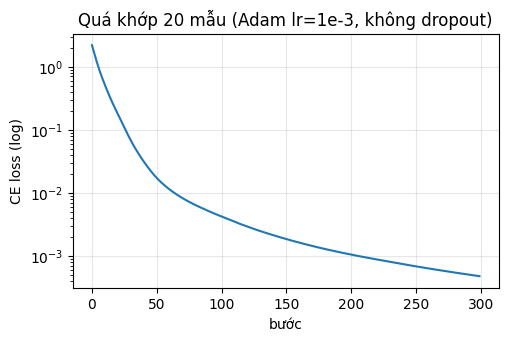

In [12]:
# 1c-2: quá khớp 20 mẫu (dropout tắt, 300 bước). Kỳ vọng: loss -> gần 0, acc = 100%
set_seed(0)
tiny = MLP((256, 128), dropout=0.0, init='he').to(device)
idx = torch.randperm(len(data['X_tr']), generator=torch.Generator().manual_seed(0))[:20].to(device)
xb20, yb20 = data['X_tr'][idx], data['y_tr'][idx]
print('nhãn của 20 mẫu:', yb20.tolist())
opt_tiny = torch.optim.Adam(tiny.parameters(), lr=1e-3)
curve = []
for step in range(300):
    tiny.train()
    loss = compute_loss(tiny(xb20), yb20, 'ce')
    opt_tiny.zero_grad(set_to_none=True)
    loss.backward()
    opt_tiny.step()
    curve.append(loss.item())
acc20 = (predict(tiny, xb20) == yb20).float().mean().item()
print(f'loss bước đầu = {curve[0]:.4f}; loss sau 300 bước = {curve[-1]:.2e}; acc trên 20 mẫu = {acc20:.0%}')
plt.figure(figsize=(5.5, 3.3))
plt.semilogy(curve)
plt.xlabel('bước')
plt.ylabel('CE loss (log)')
plt.title('Quá khớp 20 mẫu (Adam lr=1e-3, không dropout)')
plt.grid(alpha=0.3)
plt.show()
assert curve[-1] < 0.05 and acc20 == 1.0

In [13]:
# 1d: gradient có chảy tới MỌI tham số không? (một lô 512, một lần backward)
model.train()
model.zero_grad(set_to_none=True)
loss = compute_loss(model(data['X_tr'][:512]), data['y_tr'][:512], 'ce')
loss.backward()
k = 0
for name, p in model.named_parameters():
    if name.endswith('weight'):
        k += 1
    short = ('W' if name.endswith('weight') else 'b') + str(k)
    assert p.grad is not None
    g = p.grad.norm().item()
    print(f'{short:3s} {name:13s} shape {str(tuple(p.shape)):10s} ||grad|| = {g:.4e}')
    assert g > 0
print('OK: mọi tham số có gradient khác None và khác 0')

W1  net.0.weight  shape (256, 54)  ||grad|| = 4.5429e-01
b1  net.0.bias    shape (256,)     ||grad|| = 2.6839e-01
W2  net.2.weight  shape (128, 256) ||grad|| = 1.7565e+00
b2  net.2.bias    shape (128,)     ||grad|| = 3.8244e-01
W3  net.4.weight  shape (7, 128)   ||grad|| = 1.9387e+00
b3  net.4.bias    shape (7,)       ||grad|| = 5.4980e-01
OK: mọi tham số có gradient khác None và khác 0


**Nhận xét Part 1:**
- Số tham số = 47 879, logits `(8, 7)`; shape từng lớp đúng quy định.
- Loss bước 0 (seed 0) = **2,207**, cao hơn ln 7 = 1,946 khoảng 0,26. Nguyên nhân: He được áp cho **cả lớp ra**, nên logits có std ≈ 0,61 chứ không ≈ 0. Softmax vì thế không đều, và CE trung bình lớn hơn ln 7. Mức lệch phụ thuộc seed: các seed baseline cho 2,27 / 1,98 / 1,90. Khi khởi tạo `zeros`/`normal` (logits ≈ 0), loss bước 0 = 1,9459 / 1,9460, đúng bằng ln 7, xác nhận nhãn và hàm loss đúng. Lệch +0,1 đến +0,3 không phải lỗi, chỉ là logit ban đầu chưa nhỏ.
- Quá khớp 20 mẫu: loss 2,198 → 4,75e-4 sau 300 bước, acc 100%, chứng tỏ pipeline (nhãn, loss, backward, optimizer) không có lỗi.
- Mọi tham số W1, b1, W2, b2, W3, b3 đều có gradient khác 0 (‖∇W1‖ = 0,45 … ‖∇W3‖ = 1,94), nên gradient chảy tới mọi lớp.

## Part 2 — Pipeline và baseline
`run_experiment(cfg, data)` (trong `train.py`) nhận một dict cấu hình và trả về lịch sử + tóm tắt; mọi thí nghiệm sau chỉ đổi dict. Mỗi epoch ghi: train loss (eval mode, 50 000 mẫu train cố định), val loss/acc/macro-F1, `grad_norm` trung bình và max (đo **trước** clip), thời gian epoch (có `cuda.synchronize`), bộ nhớ GPU cực đại (tính từ lúc tạo model), loss bước 0, best epoch theo val loss, cờ `diverged`.

Baseline: `M-base`, He, CE, SGD+momentum 0.9, batch 512, 20 epoch, không dropout/clip, FP32. **Chọn lr bằng val** trong lưới {0.01, 0.03, 0.1, 0.3} (seed 1); các lần dò này cũng là các dòng lr của SGD+momentum trong chủ đề optimizer.

[opt-sgdm-lr0.01] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.5764  val 0.5803  acc 0.7560  F1 0.4941  |g| 0.437 (max 2.84)  1.36s
  ep  2  train 0.5250  val 0.5294  acc 0.7758  F1 0.5824  |g| 0.504 (max 1.09)  1.22s
  ep  3  train 0.4905  val 0.4947  acc 0.7906  F1 0.5968  |g| 0.603 (max 1.43)  1.36s
  ep  4  train 0.4678  val 0.4727  acc 0.8000  F1 0.6280  |g| 0.705 (max 1.57)  1.42s
  ep  5  train 0.4452  val 0.4502  acc 0.8089  F1 0.6427  |g| 0.798 (max 1.73)  1.26s
  ep  6  train 0.4243  val 0.4303  acc 0.8201  F1 0.6656  |g| 0.888 (max 2.18)  1.22s
  ep  7  train 0.4119  val 0.4175  acc 0.8252  F1 0.6798  |g| 0.915 (max 2.41)  1.24s
  ep  8  train 0.4005  val 0.4065  acc 0.8309  F1 0.6791  |g| 1.025 (max 2.17)  1.23s
  ep  9  train 0.3863  val 0.3921  acc 0.8387  F1 0.6941  |g| 1.042 (max 2.26)  1.25s
  ep 10  train 0.3746  val 0.3816  acc 0.8431  F1 0.7180  |g| 1.178 (max 3.14)  1.24s
  ep 11  train 0.3674  val 0.3739  acc 0.8446  F1 0.7131  |g| 1.141 (max 3.00)  1.

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
opt-sgdm-lr0.01,sgd_momentum,0.01,512,20,2.2691,0.3110,0.0115,0.8747,0.7613,NaN,-,1.2724,False
opt-sgdm-lr0.03,sgd_momentum,0.03,512,20,2.2691,0.2660,0.0187,0.8921,0.8170,NaN,-,1.2794,False
opt-sgdm-lr0.1,sgd_momentum,0.10,512,18,2.2691,0.2379,0.0207,0.9054,0.8390,NaN,-,1.2682,False
opt-sgdm-lr0.3,sgd_momentum,0.30,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,NaN,-,1.3008,False


=> lr baseline (chọn theo val macro-F1) = 0.3


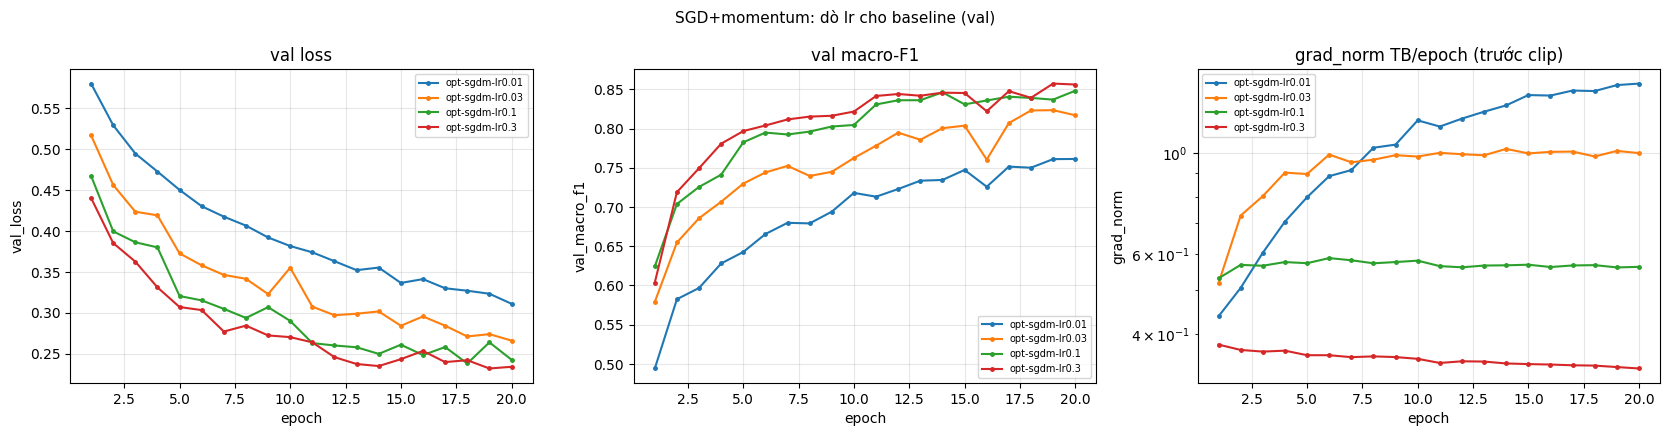

In [14]:
# 2a: dò lr cho baseline bằng VAL
BASE = dict(DEFAULT_CFG)
LR_GRID_SGDM = [0.01, 0.03, 0.1, 0.3]
SWEEP_IDS = []
for lr in LR_GRID_SGDM:
    eid = f'opt-sgdm-lr{lr:g}'
    run({**BASE, 'exp_id': eid, 'group': 'optimizer', 'lr': lr,
         'description': f'SGD+momentum 0.9, lr={lr:g} (dò lr baseline)',
         'notes': 'dò lr baseline trên val; dòng có lr được chọn trùng cấu hình base-s1'})
    SWEEP_IDS.append(eid)
table(SWEEP_IDS)
BASE_LR = RESULTS[best_of(SWEEP_IDS)]['cfg']['lr']
BASE['lr'] = BASE_LR
print('=> lr baseline (chọn theo val macro-F1) =', BASE_LR)
plot_compare([RESULTS[e] for e in SWEEP_IDS], ['val_loss', 'val_macro_f1', 'grad_norm'],
             f'{OUT_DIR}/figures/compare_lr_sgdm.png', 'SGD+momentum: dò lr cho baseline (val)')

[base-s1] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.4350  val 0.4404  acc 0.8127  F1 0.6037  |g| 0.379 (max 2.84)  1.23s
  ep  2  train 0.3784  val 0.3852  acc 0.8383  F1 0.7190  |g| 0.369 (max 0.64)  1.21s
  ep  3  train 0.3538  val 0.3625  acc 0.8464  F1 0.7494  |g| 0.365 (max 0.67)  1.18s
  ep  4  train 0.3180  val 0.3310  acc 0.8650  F1 0.7807  |g| 0.367 (max 0.71)  1.21s
  ep  5  train 0.2932  val 0.3070  acc 0.8748  F1 0.7968  |g| 0.359 (max 0.56)  1.22s
  ep  6  train 0.2929  val 0.3032  acc 0.8760  F1 0.8039  |g| 0.359 (max 0.72)  1.26s
  ep  7  train 0.2650  val 0.2770  acc 0.8860  F1 0.8116  |g| 0.355 (max 0.64)  1.38s
  ep  8  train 0.2693  val 0.2842  acc 0.8847  F1 0.8152  |g| 0.357 (max 0.59)  1.32s
  ep  9  train 0.2544  val 0.2722  acc 0.8899  F1 0.8163  |g| 0.355 (max 0.55)  1.18s
  ep 10  train 0.2528  val 0.2702  acc 0.8899  F1 0.8217  |g| 0.352 (max 0.63)  1.19s
  ep 11  train 0.2474  val 0.2638  acc 0.8944  F1 0.8415  |g| 0.345 (max 0.54)  1.19s
  ep

,val_acc,val_macro_f1,best_val_loss
base-s1,0.9090,0.8573,0.2318
base-s2,0.9144,0.8618,0.2145
base-s3,0.9121,0.8630,0.2208
mean,0.9118,0.8607,0.2224
std,0.0027,0.0030,0.0088


baseline val macro-F1 = 0.8607 ± 0.0030  -> ngưỡng nhiễu 2σ = 0.0060
baseline val acc      = 0.9118 ± 0.0027  (mốc đoán đa số 0.4876)
base-s1 val_loss 5 epoch cuối: [0.2533 0.2396 0.2419 0.2318 0.2339]
base-s1 train_loss 5 epoch cuối: [0.2296 0.2178 0.2161 0.2068 0.2057]


,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
base-s2,sgd_momentum,0.3,512,16,1.9782,0.2145,0.0288,0.9144,0.8618,0.0011,Không,1.2747,False
base-s3,sgd_momentum,0.3,512,18,1.9005,0.2208,0.0250,0.9121,0.8630,0.0023,Không,1.2590,False


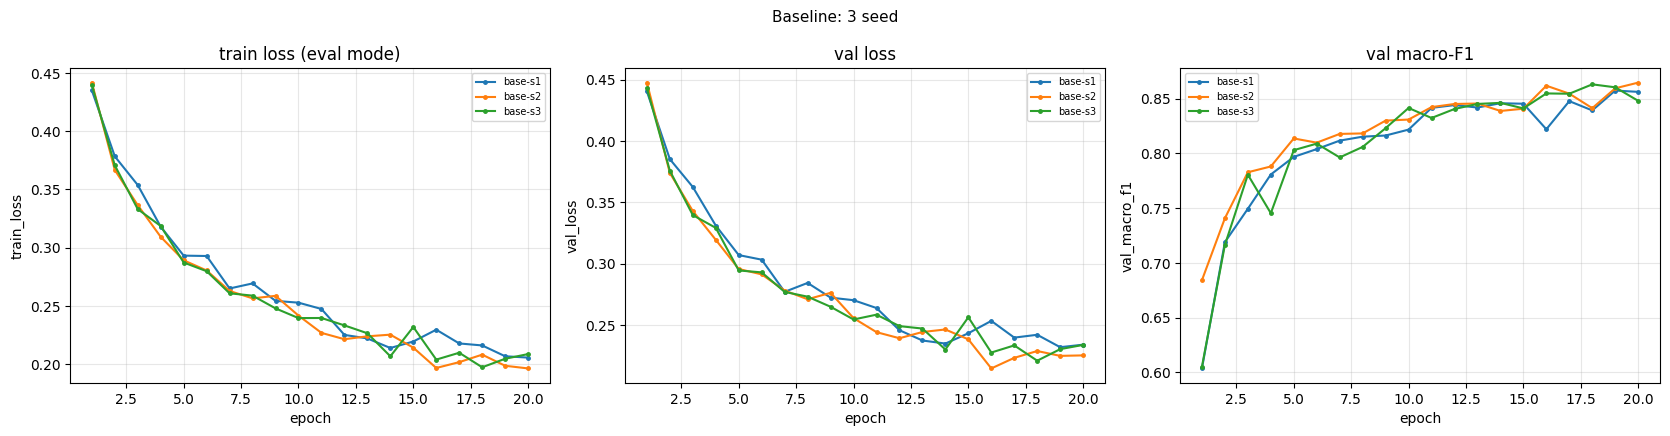

In [15]:
# 2b: baseline với 3 seed -> độ nhiễu giữa các seed (ngưỡng 2σ dùng cho mọi so sánh sau)
SEEDS = [1, 2, 3]
BASE_IDS = [f'base-s{s}' for s in SEEDS]
for s in SEEDS:
    run({**BASE, 'exp_id': f'base-s{s}', 'group': 'baseline', 'seed': s,
         'description': f'Baseline M-base (SGD+momentum lr={BASE_LR:g}), seed {s}'}, save_ckpt=(s == 1))
seed_df = pd.DataFrame([{k: f(RESULTS[e]['summary'][k]) for k in ('val_acc', 'val_macro_f1', 'best_val_loss')}
                        for e in BASE_IDS], index=BASE_IDS)
stats = seed_df.agg(['mean', 'std'])   # std mẫu (ddof=1), giống STDEV của sheet Seeds
display(pd.concat([seed_df, stats]).round(4))
BASE_F1_MEAN = stats.loc['mean', 'val_macro_f1']
BASE_F1_STD = stats.loc['std', 'val_macro_f1']
NOISE_2SIGMA = 2 * BASE_F1_STD
acc_m, acc_s = stats.loc['mean', 'val_acc'], stats.loc['std', 'val_acc']
print(f'baseline val macro-F1 = {BASE_F1_MEAN:.4f} ± {BASE_F1_STD:.4f}  -> ngưỡng nhiễu 2σ = {NOISE_2SIGMA:.4f}')
print(f'baseline val acc      = {acc_m:.4f} ± {acc_s:.4f}  (mốc đoán đa số 0.4876)')
hb = RESULTS['base-s1']['history']
print('base-s1 val_loss 5 epoch cuối:', np.round(hb['val_loss'][-5:], 4))
print('base-s1 train_loss 5 epoch cuối:', np.round(hb['train_loss'][-5:], 4))
table(BASE_IDS)
plot_compare([RESULTS[e] for e in BASE_IDS], ['train_loss', 'val_loss', 'val_macro_f1'],
             f'{OUT_DIR}/figures/compare_baseline_seeds.png', 'Baseline: 3 seed')

**Nhận xét baseline:**
- Dò lr (seed 1): 0,01 → val macro-F1 0,761; 0,03 → 0,817; 0,1 → 0,839; **0,3 → 0,857**, nên chọn lr = 0,3. Đây là đầu trên của lưới (hạn chế: chưa thử 0,5–1,0 cho SGD+momentum; lr 3,0 thì sập, xem chủ đề clipping).
- 3 seed: val macro-F1 = **0,8607 ± 0,0030**, val acc = 0,9118 ± 0,0027, vượt xa mốc đoán lớp đa số (0,4876). **Ngưỡng nhiễu 2σ = 0,0060** được dùng cho mọi so sánh sau.
- Hình dạng đường cong: train loss và val loss **cùng giảm** đến cuối (base-s1: val 0,253 → 0,232 ở 5 epoch cuối), khoảng cách val − train chỉ ≈ 0,025–0,029, best epoch 16–19/20. Mô hình **chưa hội tụ và chưa quá khớp** (thiếu khớp nhẹ). Val loss có vài gai nhỏ (epoch 16) do lr 0,3 khá lớn.

## Part 3 — Thí nghiệm
Mỗi thí nghiệm đổi **một** yếu tố so với baseline (seed 1, 20 epoch, cùng split), trừ khi ghi rõ trong `notes`. So sánh bằng **val macro-F1** với trung bình 3 seed baseline; chênh lệch nhỏ hơn 2σ được coi là *chưa kết luận được*.

### Chủ đề 1 — Hàm mất mát: CE vs MSE (`loss-mse`, `loss-mse-lr3x`)
**Dự đoán trước:** MSE tính trên logit và one-hot (`nn.MSELoss`, trung bình trên B·7 phần tử) có gradient theo logit là `2(z − y)/(7B)`: tuyến tính theo sai số, nhỏ hơn CE (`(softmax − y)/B`) khoảng 3,5 lần, và kéo mọi logit về đúng 0/1 thay vì chỉ cần lớp đúng cao nhất. Khi một mẫu bị dự đoán sai nặng, CE vẫn cho gradient gần ±1 (không bão hoà) còn MSE thì không ưu tiên sửa mẫu đó. Dự đoán: cùng lr, MSE hội tụ chậm hơn và macro-F1 thấp hơn rõ (vượt 2σ), nhất là ở lớp hiếm. Tăng lr ×3 bù được một phần độ lớn gradient nhưng vẫn kém CE. Không so loss trực tiếp vì hai loss khác thang đo.

[loss-mse] step0 val loss = 0.6359  (ln7 = 1.9459)
  ep  1  train 0.0457  val 0.0458  acc 0.7780  F1 0.4835  |g| 0.057 (max 2.26)  1.29s
  ep  2  train 0.0408  val 0.0412  acc 0.8040  F1 0.5397  |g| 0.055 (max 0.11)  1.33s
  ep  3  train 0.0386  val 0.0390  acc 0.8208  F1 0.6292  |g| 0.060 (max 0.13)  1.46s
  ep  4  train 0.0363  val 0.0367  acc 0.8309  F1 0.6561  |g| 0.064 (max 0.14)  1.44s
  ep  5  train 0.0347  val 0.0351  acc 0.8385  F1 0.6589  |g| 0.064 (max 0.12)  1.26s
  ep  6  train 0.0338  val 0.0343  acc 0.8458  F1 0.7063  |g| 0.068 (max 0.11)  1.30s
  ep  7  train 0.0327  val 0.0332  acc 0.8501  F1 0.6896  |g| 0.066 (max 0.12)  1.26s
  ep  8  train 0.0319  val 0.0323  acc 0.8559  F1 0.7253  |g| 0.068 (max 0.12)  1.26s
  ep  9  train 0.0312  val 0.0318  acc 0.8567  F1 0.7027  |g| 0.068 (max 0.12)  1.39s
  ep 10  train 0.0308  val 0.0314  acc 0.8609  F1 0.7304  |g| 0.069 (max 0.12)  1.36s
  ep 11  train 0.0306  val 0.0311  acc 0.8627  F1 0.7356  |g| 0.068 (max 0.12)  1.31s
  e

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
loss-mse,sgd_momentum,0.3,512,20,0.6359,0.0274,0.0010,0.8803,0.7726,-0.0881,Có,1.3259,False
loss-mse-lr3x,sgd_momentum,0.9,512,19,0.6359,0.0326,0.0004,0.8584,0.7485,-0.1122,Có,1.3732,False


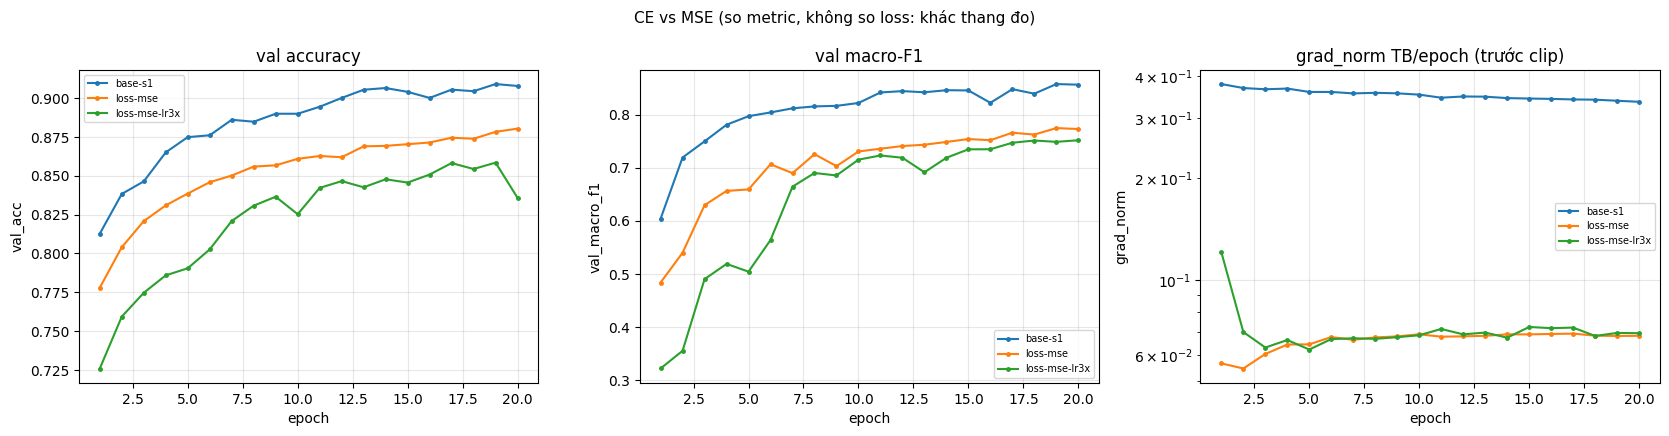

In [16]:
LOSS_IDS = ['loss-mse', 'loss-mse-lr3x']
run({**BASE, 'exp_id': 'loss-mse', 'group': 'loss', 'loss': 'mse',
     'description': 'MSE trên one-hot thay cho CE (cùng lr baseline)',
     'notes': 'MSE = nn.MSELoss(mean) giữa logit và one-hot, trung bình trên B*7 phần tử, không có hệ số 1/2'})
run({**BASE, 'exp_id': 'loss-mse-lr3x', 'group': 'loss', 'loss': 'mse', 'lr': 3 * BASE_LR,
     'description': f'MSE, lr = 3 x baseline = {3 * BASE_LR:g}',
     'notes': 'đổi 2 yếu tố có chủ đích (loss + lr): gradient MSE nhỏ hơn CE nên thử bù bằng lr'})
table(['base-s1'] + LOSS_IDS)
plot_compare([RESULTS[e] for e in ['base-s1'] + LOSS_IDS], ['val_acc', 'val_macro_f1', 'grad_norm'],
             f'{OUT_DIR}/figures/compare_loss.png', 'CE vs MSE (so metric, không so loss: khác thang đo)')

**Đối chiếu sau khi chạy (loss):** khớp phần lớn dự đoán.
- `loss-mse`: val macro-F1 **0,7726** (−0,088 so với TB baseline, vượt 2σ = 0,006); acc 0,8803 (−0,031). Macro-F1 giảm gần gấp 3 lần acc, tức các **lớp hiếm bị ảnh hưởng nhiều nhất**, đúng như dự đoán.
- `grad_norm` của MSE ≈ 0,06–0,07, so với CE ≈ 0,35 (nhỏ hơn khoảng 5 lần, ảnh `compare_loss.png`). Gradient MSE `2(z−y)/(7B)` vừa nhỏ vừa không tập trung vào mẫu sai, còn CE đẩy mạnh lớp đúng nhờ `softmax − y`.
- **Khác dự đoán:** tăng lr ×3 (`loss-mse-lr3x`, lr 0,9) **không** bù được mà còn kém hơn (0,7485). Grad norm gần như không đổi, nhưng các epoch đầu dao động mạnh (F1 epoch 1 chỉ 0,32): lr 0,9 với momentum 0,9 quá lớn cho lớp ra. Vấn đề của MSE nằm ở **hướng** gradient (kéo mọi logit về 0/1) chứ không chỉ ở độ lớn.
- Loss của CE và MSE không so trực tiếp (khác thang đo); chỉ so acc và macro-F1.

### Chủ đề 2 — Bộ tối ưu hoá (`opt-*`)
Mỗi bộ thử ≥ 2 lr cách nhau ~3 lần, so ở **lr tốt nhất của mỗi bộ** (theo val):
- SGD+momentum 0.9: lr ∈ {0.01, 0.03, 0.1, 0.3} (đã chạy ở Part 2)
- SGD (không momentum): lr ∈ {0.1, 0.3, 1.0}
- Adam (β=(0.9, 0.999), ε=1e-8, wd=0): lr ∈ {3e-4, 1e-3, 3e-3}
- AdamW (β, ε như Adam, wd=0.01): lr ∈ {1e-3, 3e-3}; thêm AdamW wd=0, lr=1e-3 để kiểm chứng trùng Adam.

**Dự đoán trước:** Adam/AdamW chia bước cho `sqrt(v̂)` nên mỗi tham số đi bước cỡ lr bất kể độ lớn gradient: lên nhanh ở vài epoch đầu và ít nhạy lr hơn. SGD thuần ở cùng lr danh nghĩa chậm hơn SGD+momentum khoảng 10 lần (momentum 0.9 ~ lr hiệu dụng `lr/(1−μ)`), nên SGD cần lr lớn hơn khoảng 10 lần. Ở lr tốt nhất của mỗi bộ: Adam ≈ AdamW ≥ SGD+momentum > SGD; khoảng cách giữa Adam và SGD+momentum có thể nhỏ (gần 2σ). AdamW với wd=0 phải cho kết quả gần như trùng Adam.

[opt-sgd-lr0.1] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.5922  val 0.5943  acc 0.7426  F1 0.4757  |g| 0.590 (max 2.84)  1.16s
  ep  2  train 0.5310  val 0.5343  acc 0.7728  F1 0.5827  |g| 0.676 (max 2.08)  1.14s
  ep  3  train 0.5387  val 0.5431  acc 0.7671  F1 0.5645  |g| 0.748 (max 2.11)  1.24s
  ep  4  train 0.6005  val 0.6072  acc 0.7352  F1 0.5899  |g| 0.831 (max 2.72)  1.23s
  ep  5  train 0.4671  val 0.4697  acc 0.7981  F1 0.6179  |g| 0.889 (max 2.40)  1.23s
  ep  6  train 0.4444  val 0.4494  acc 0.8131  F1 0.6760  |g| 0.887 (max 2.78)  1.28s
  ep  7  train 0.5049  val 0.5073  acc 0.7730  F1 0.6605  |g| 0.909 (max 2.57)  1.36s
  ep  8  train 0.4360  val 0.4413  acc 0.8130  F1 0.6442  |g| 0.929 (max 2.39)  1.34s
  ep  9  train 0.4136  val 0.4203  acc 0.8244  F1 0.6537  |g| 0.964 (max 2.80)  1.20s
  ep 10  train 0.4312  val 0.4361  acc 0.8100  F1 0.6923  |g| 0.974 (max 2.46)  1.18s
  ep 11  train 0.4642  val 0.4670  acc 0.7921  F1 0.6783  |g| 0.964 (max 2.32)  1.19

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
opt-sgdm-lr0.01,sgd_momentum,0.0100,512,20,2.2691,0.3110,0.0115,0.8747,0.7613,-0.0995,Có,1.2724,False
opt-sgdm-lr0.03,sgd_momentum,0.0300,512,20,2.2691,0.2660,0.0187,0.8921,0.8170,-0.0438,Có,1.2794,False
opt-sgdm-lr0.1,sgd_momentum,0.1000,512,18,2.2691,0.2379,0.0207,0.9054,0.8390,-0.0217,Có,1.2682,False
opt-sgdm-lr0.3,sgd_momentum,0.3000,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.3008,False
opt-sgd-lr0.1,sgd,0.1000,512,18,2.2691,0.3475,0.0103,0.8580,0.7551,-0.1057,Có,1.2268,False
opt-sgd-lr0.3,sgd,0.3000,512,18,2.2691,0.2803,0.0131,0.8871,0.8163,-0.0444,Có,1.2247,False
opt-sgd-lr1,sgd,1.0000,512,18,2.2691,0.2522,0.0246,0.9000,0.8344,-0.0263,Có,1.2121,False
opt-adam-lr0.0003,adam,0.0003,512,20,2.2691,0.3135,0.0104,0.8727,0.7877,-0.0730,Có,1.3975,False
opt-adam-lr0.001,adam,0.0010,512,19,2.2691,0.2494,0.0203,0.8993,0.8456,-0.0152,Có,1.4251,False


lr tốt nhất của từng bộ tối ưu (theo val macro-F1): {'sgd_momentum': 'opt-sgdm-lr0.3', 'sgd': 'opt-sgd-lr1', 'adam': 'opt-adam-lr0.003', 'adamw': 'opt-adamw-lr0.003'}


,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
opt-sgdm-lr0.3,sgd_momentum,0.300,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.3008,False
opt-sgd-lr1,sgd,1.000,512,18,2.2691,0.2522,0.0246,0.9000,0.8344,-0.0263,Có,1.2121,False
opt-adam-lr0.003,adam,0.003,512,19,2.2691,0.2145,0.0290,0.9153,0.8677,0.0070,Có,1.5190,False
opt-adamw-lr0.003,adamw,0.003,512,18,2.2691,0.2161,0.0223,0.9130,0.8646,0.0039,Không,1.4072,False


Adam vs AdamW(wd=0), lr=1e-3: best_val_loss 0.249411 vs 0.249411


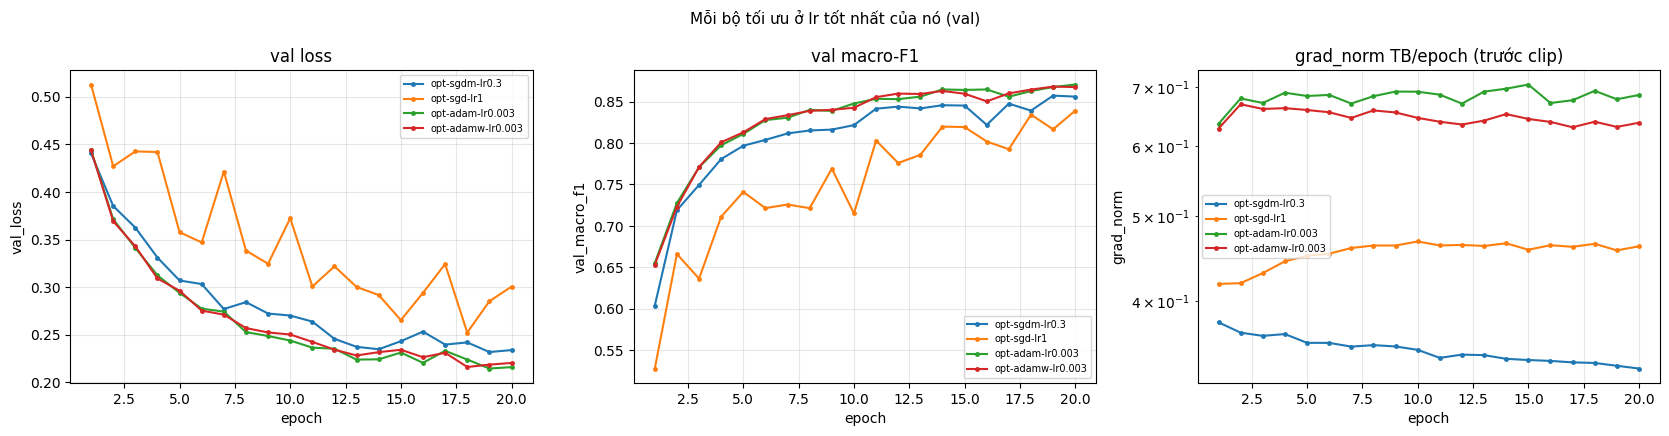

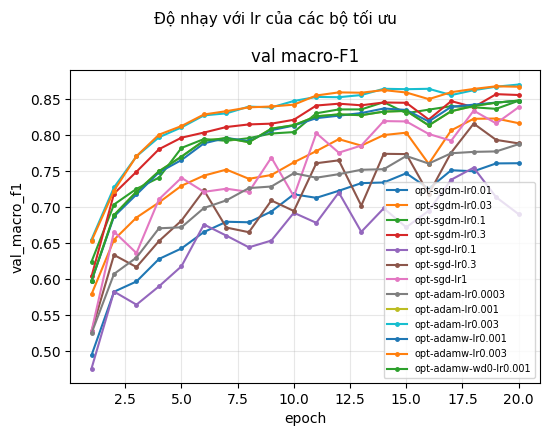

In [17]:
OPT_GRID = {'sgd': [0.1, 0.3, 1.0], 'adam': [3e-4, 1e-3, 3e-3], 'adamw': [1e-3, 3e-3]}
OPT_IDS = {'sgd_momentum': SWEEP_IDS}
for name, lrs in OPT_GRID.items():
    OPT_IDS[name] = []
    for lr in lrs:
        wd = 0.01 if name == 'adamw' else 0.0
        eid = f'opt-{name}-lr{lr:g}'
        run({**BASE, 'exp_id': eid, 'group': 'optimizer', 'optimizer': name, 'lr': lr, 'weight_decay': wd,
             'description': f'{name} lr={lr:g}, weight_decay={wd:g}'})
        OPT_IDS[name].append(eid)
run({**BASE, 'exp_id': 'opt-adamw-wd0-lr0.001', 'group': 'optimizer', 'optimizer': 'adamw', 'lr': 1e-3,
     'weight_decay': 0.0, 'description': 'AdamW wd=0, lr=1e-3 (kiểm chứng: phải trùng Adam lr=1e-3)'})
ALL_OPT = [e for ids in OPT_IDS.values() for e in ids] + ['opt-adamw-wd0-lr0.001']
print('Tất cả lần chạy của chủ đề optimizer:')
table(ALL_OPT)
BEST_OPT = {name: best_of(ids) for name, ids in OPT_IDS.items()}
print('lr tốt nhất của từng bộ tối ưu (theo val macro-F1):', BEST_OPT)
table(list(BEST_OPT.values()))
a = RESULTS['opt-adam-lr0.001']['summary']
b = RESULTS['opt-adamw-wd0-lr0.001']['summary']
print(f"Adam vs AdamW(wd=0), lr=1e-3: best_val_loss {f(a['best_val_loss']):.6f} vs {f(b['best_val_loss']):.6f}")
plot_compare([RESULTS[e] for e in BEST_OPT.values()], ['val_loss', 'val_macro_f1', 'grad_norm'],
             f'{OUT_DIR}/figures/compare_optimizer.png', 'Mỗi bộ tối ưu ở lr tốt nhất của nó (val)')
plot_compare([RESULTS[e] for e in ALL_OPT], ['val_macro_f1'],
             f'{OUT_DIR}/figures/compare_optimizer_all_lr.png', 'Độ nhạy với lr của các bộ tối ưu')

**Đối chiếu sau khi chạy (optimizer):**
- So ở lr tốt nhất của mỗi bộ (val macro-F1): **Adam lr 3e-3: 0,8677** · AdamW lr 3e-3 (wd 0,01): 0,8646 · SGD+momentum lr 0,3: 0,8573 (TB 3 seed 0,8607) · SGD lr 1,0: 0,8344.
- Adam hơn TB baseline +0,0070, **vừa sát ngưỡng** 2σ = 0,0060; AdamW +0,0039 **không vượt** nhiễu. Adam vs AdamW chênh 0,003, nằm trong nhiễu. Kết luận chắc chắn được: SGD thuần kém nhất (−0,026, vượt 2σ). Adam và SGD+momentum gần như ngang nhau. Hơn nữa, σ mới chỉ đo cho SGD+momentum, chưa đo cho Adam.
- SGD thuần cần lr lớn hơn khoảng 10 lần: SGD lr 1,0 (0,834) ≈ SGD+momentum lr 0,1 (0,839), khớp với lr hiệu dụng `lr/(1−μ)` = 10·lr.
- **AdamW wd = 0 trùng Adam đúng từng chữ số** (best_val_loss 0,249411 ở cả hai), kiểm chứng rằng hai bộ chỉ khác nhau ở cách áp weight decay.
- Độ nhạy lr: nếu không chỉnh lr thì kết luận đảo chiều tuỳ cặp lr. Ví dụ Adam 1e-3 (0,846) "thắng" SGD+momentum 0,01 (0,761) tới 0,084, nhưng Adam 3e-4 (0,788) lại "thua" SGD+momentum 0,3 (0,857). Adam nhanh hơn ở vài epoch đầu (ảnh `compare_optimizer.png`), đúng như dự đoán, nhờ bước được chuẩn hoá theo √v̂.
- Hạn chế: lr tốt nhất của Adam (3e-3) và SGD (1,0) nằm ở **đầu lưới**, nên có thể còn tốt hơn ở lr lớn hơn.

### Chủ đề 3 — Hyper-parameter (`hp-*`)
Batch 128 / 2048 (giữ lr), batch 2048 với lr ×4 (quy tắc tăng lr tuyến tính theo lô, không warmup), độ rộng `M-wide`, độ sâu `M-deep`, weight decay 5e-4.

**Dự đoán trước:** cùng 20 epoch, batch 128 có gấp 4 lần số bước cập nhật nên val tốt hơn nhưng mỗi epoch chậm hơn nhiều (nhiều lần gọi kernel hơn). Batch 2048 giữ nguyên lr chỉ có 1/4 số bước nên kém rõ. Tăng lr ×4 bù lại được phần lớn, nhưng có thể dao động vì không warmup. Baseline đang chưa khớp (train ≈ val), nên `M-wide`/`M-deep` (năng lực lớn hơn) sẽ tăng val macro-F1, còn weight decay có thể làm giảm nhẹ.

[hp-bs128] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.4799  val 0.4816  acc 0.7985  F1 0.5729  |g| 0.451 (max 2.99)  5.00s
  ep  2  train 0.4491  val 0.4548  acc 0.8071  F1 0.6768  |g| 0.438 (max 0.75)  4.77s
  ep  3  train 0.4582  val 0.4669  acc 0.8143  F1 0.6435  |g| 0.440 (max 2.60)  5.18s
  ep  4  train 0.3913  val 0.4043  acc 0.8400  F1 0.7352  |g| 0.443 (max 1.08)  4.72s
  ep  5  train 0.3565  val 0.3676  acc 0.8503  F1 0.7368  |g| 0.440 (max 0.95)  4.72s
  ep  6  train 0.3666  val 0.3816  acc 0.8535  F1 0.7162  |g| 0.439 (max 1.52)  5.09s
  ep  7  train 0.3652  val 0.3729  acc 0.8579  F1 0.7165  |g| 0.441 (max 1.14)  4.84s
  ep  8  train 0.3347  val 0.3474  acc 0.8647  F1 0.7764  |g| 0.440 (max 1.06)  5.12s
  ep  9  train 0.3859  val 0.3924  acc 0.8590  F1 0.7696  |g| 0.441 (max 5.64)  4.83s
  ep 10  train 0.3396  val 0.3556  acc 0.8654  F1 0.7785  |g| 0.446 (max 2.47)  6.85s
  ep 11  train 0.3261  val 0.3399  acc 0.8687  F1 0.7795  |g| 0.440 (max 1.17)  4.81s
  e

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
hp-bs128,sgd_momentum,0.3,128,14,2.2691,0.3209,0.0200,0.8749,0.7951,-0.0656,Có,5.0092,False
hp-bs2048,sgd_momentum,0.3,2048,18,2.2691,0.2437,0.0193,0.9014,0.8338,-0.0269,Có,0.3645,False
hp-bs2048-lr4x,sgd_momentum,1.2,2048,11,2.2691,1.2052,0.0017,0.4876,0.0936,-0.7671,Có,0.3374,False
hp-wide,sgd_momentum,0.3,512,20,1.9182,0.1998,0.0328,0.9226,0.8747,0.0140,Có,1.2575,False
hp-deep,sgd_momentum,0.3,512,20,1.9099,0.2222,0.0309,0.9138,0.8413,-0.0195,Có,1.4129,False
hp-wd5e-4,sgd_momentum,0.3,512,20,2.2691,0.3840,0.0043,0.8413,0.7035,-0.1572,Có,1.3198,False


số bước cập nhật: {'base-s1': 14540, 'hp-bs128': 58120, 'hp-bs2048': 3640, 'hp-bs2048-lr4x': 3640, 'hp-wide': 14540, 'hp-deep': 14540, 'hp-wd5e-4': 14540}


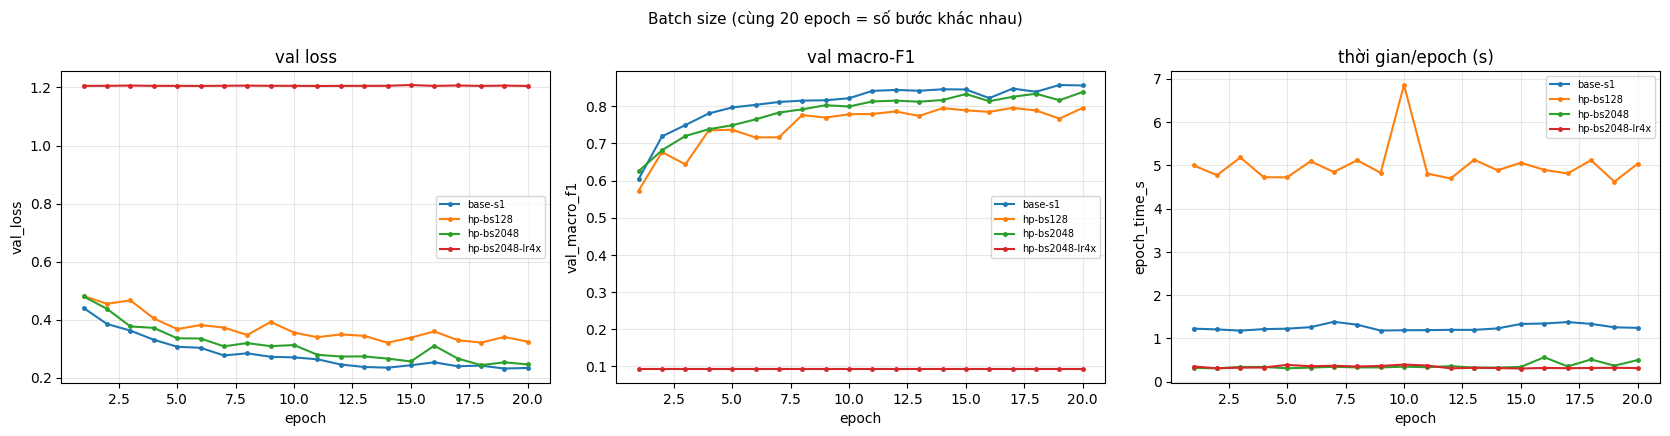

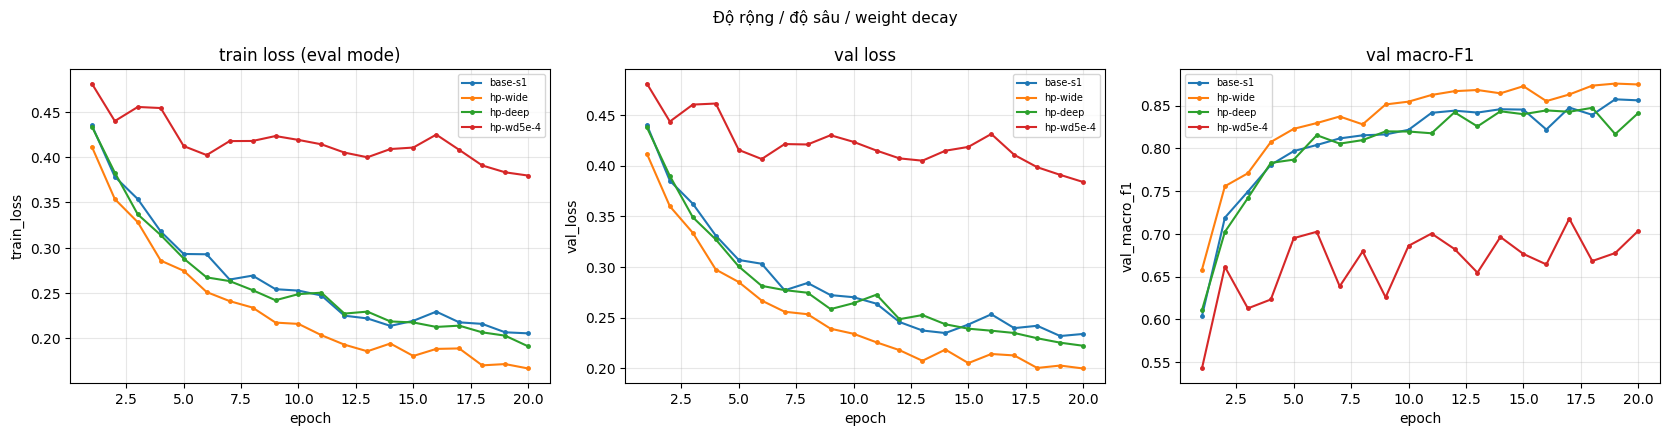

In [18]:
HP = [
    dict(exp_id='hp-bs128', batch=128, description='batch 128, giữ lr (gấp 4 số bước/epoch)'),
    dict(exp_id='hp-bs2048', batch=2048, description='batch 2048, giữ lr (1/4 số bước/epoch)'),
    dict(exp_id='hp-bs2048-lr4x', batch=2048, lr=4 * BASE_LR,
         description=f'batch 2048 + lr x4 = {4 * BASE_LR:g} (quy tắc tuyến tính, không warmup)',
         notes='đổi 2 yếu tố có chủ đích (batch + lr) để thử quy tắc tăng lr theo lô'),
    dict(exp_id='hp-wide', hidden=(512, 256), description='M-wide 54-512-256-7 (161 287 tham số)'),
    dict(exp_id='hp-deep', hidden=(256, 128, 64), description='M-deep 54-256-128-64-7 (55 687 tham số)'),
    dict(exp_id='hp-wd5e-4', weight_decay=5e-4, description='weight decay 5e-4 (L2 trong SGD+momentum)'),
]
for hcfg in HP:
    run({**BASE, 'group': 'hparam', **hcfg})
HP_IDS = [hcfg['exp_id'] for hcfg in HP]
table(['base-s1'] + HP_IDS)
print('số bước cập nhật:', {e: RESULTS[e]['summary']['n_steps'] for e in ['base-s1'] + HP_IDS})
plot_compare([RESULTS[e] for e in ['base-s1', 'hp-bs128', 'hp-bs2048', 'hp-bs2048-lr4x']],
             ['val_loss', 'val_macro_f1', 'epoch_time_s'], f'{OUT_DIR}/figures/compare_hparam_batch.png',
             'Batch size (cùng 20 epoch = số bước khác nhau)')
plot_compare([RESULTS[e] for e in ['base-s1', 'hp-wide', 'hp-deep', 'hp-wd5e-4']],
             ['train_loss', 'val_loss', 'val_macro_f1'], f'{OUT_DIR}/figures/compare_hparam_arch.png',
             'Độ rộng / độ sâu / weight decay')

**Đối chiếu sau khi chạy (hyper-parameter):** nhiều điểm **khác dự đoán**.
- `hp-bs128` (58 120 bước, gấp 4): **0,7951** (−0,066), 5,0 s/epoch, chậm gấp 4. Dự đoán "tốt hơn" là **sai**: giữ lr = 0,3 khi giảm batch 4 lần làm nhiễu gradient tăng khoảng 4 lần (tỉ lệ lr/batch tăng 4 lần). Val dao động, grad_norm max có gai tới ~5. Theo quy tắc tuyến tính, lr đúng cho batch 128 phải khoảng 0,075.
- `hp-bs2048` (3 640 bước, bằng 1/4): 0,8338 (−0,027), chỉ 0,36 s/epoch (nhanh hơn 3,5 lần), đúng dự đoán: ít bước hơn nên kém hơn.
- `hp-bs2048-lr4x` (lr 1,2, không warmup): **sụp đổ**, acc 0,4876 và macro-F1 0,094 (đoán toàn lớp đa số), val loss kẹt ở 1,205 = entropy của phân bố lớp. Epoch 1 có gai grad_norm ≈ 14, sau đó grad ≈ 0,03: ReLU chết và mạng chỉ còn bias. Quy tắc tăng lr theo lô **cần warmup**; dự đoán "bù lại được" là sai. Cờ `diverged` = N vì loss vẫn hữu hạn, nhưng đây thực chất là thất bại huấn luyện.
- `hp-wide`: **0,8747** (+0,014, vượt 2σ), cùng thời gian/epoch (1,26 s) vì GPU chưa bão hoà. Khớp dự đoán: mô hình đang thiếu năng lực.
- `hp-deep`: 0,8413 (−0,019). **Khác dự đoán.** Tuy vậy best_val_loss 0,2222 vẫn nằm trong khoảng 3 seed baseline (0,2145–0,2318), nên phần chênh F1 chủ yếu đến từ các lớp hiếm. Chỉ có 1 seed nên chưa kết luận được.
- `hp-wd5e-4`: **0,7035** (−0,157), train loss 0,380 so với 0,206. Với lr 0,3, mỗi bước co trọng số theo hệ số lr·λ = 1,5e-4, nhân lên qua 14 540 bước là một lực kéo rất mạnh. Mô hình vốn đã thiếu khớp nên càng thiếu khớp hơn. Dự đoán "giảm nhẹ" là sai về mức độ.

### Chủ đề 4 — Dropout (`drop-0.1`, `drop-0.3`, `drop-0.5`)
**Dự đoán trước:** sau 20 epoch baseline hầu như chưa quá khớp (val loss ≈ train loss, val còn giảm), nên dropout là "thuốc" cho một bệnh chưa có. Nó chủ yếu thêm nhiễu và làm chậm học: q = 0,1 gần như không đổi (trong 2σ), q = 0,3 và 0,5 làm val macro-F1 giảm rõ. Khoảng cách val − train (train đo ở eval mode) có thể nhỏ lại hoặc âm.

[drop-0.1] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.4516  val 0.4527  acc 0.8045  F1 0.6019  |g| 0.335 (max 2.90)  1.33s
  ep  2  train 0.3923  val 0.3955  acc 0.8310  F1 0.7082  |g| 0.306 (max 0.42)  1.35s
  ep  3  train 0.3700  val 0.3729  acc 0.8435  F1 0.7166  |g| 0.305 (max 0.50)  1.30s
  ep  4  train 0.3379  val 0.3427  acc 0.8577  F1 0.7568  |g| 0.304 (max 0.67)  1.34s
  ep  5  train 0.3186  val 0.3254  acc 0.8635  F1 0.7587  |g| 0.300 (max 0.60)  1.34s
  ep  6  train 0.3059  val 0.3144  acc 0.8689  F1 0.7793  |g| 0.300 (max 0.61)  1.38s
  ep  7  train 0.2938  val 0.3005  acc 0.8745  F1 0.8010  |g| 0.297 (max 0.70)  1.51s
  ep  8  train 0.2830  val 0.2931  acc 0.8784  F1 0.7942  |g| 0.294 (max 0.54)  1.52s
  ep  9  train 0.2760  val 0.2869  acc 0.8807  F1 0.7976  |g| 0.293 (max 0.56)  1.34s
  ep 10  train 0.2733  val 0.2825  acc 0.8839  F1 0.8145  |g| 0.293 (max 0.57)  1.31s
  ep 11  train 0.2653  val 0.2774  acc 0.8832  F1 0.8110  |g| 0.289 (max 0.44)  1.36s
  e

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
drop-0.1,sgd_momentum,0.3,512,20,2.2691,0.2400,0.0147,0.9025,0.8385,-0.0222,Có,1.3807,False
drop-0.3,sgd_momentum,0.3,512,20,2.2691,0.3141,0.0059,0.8720,0.7824,-0.0783,Có,1.3805,False
drop-0.5,sgd_momentum,0.3,512,20,2.2691,0.4249,0.0039,0.8196,0.5784,-0.2823,Có,1.3912,False


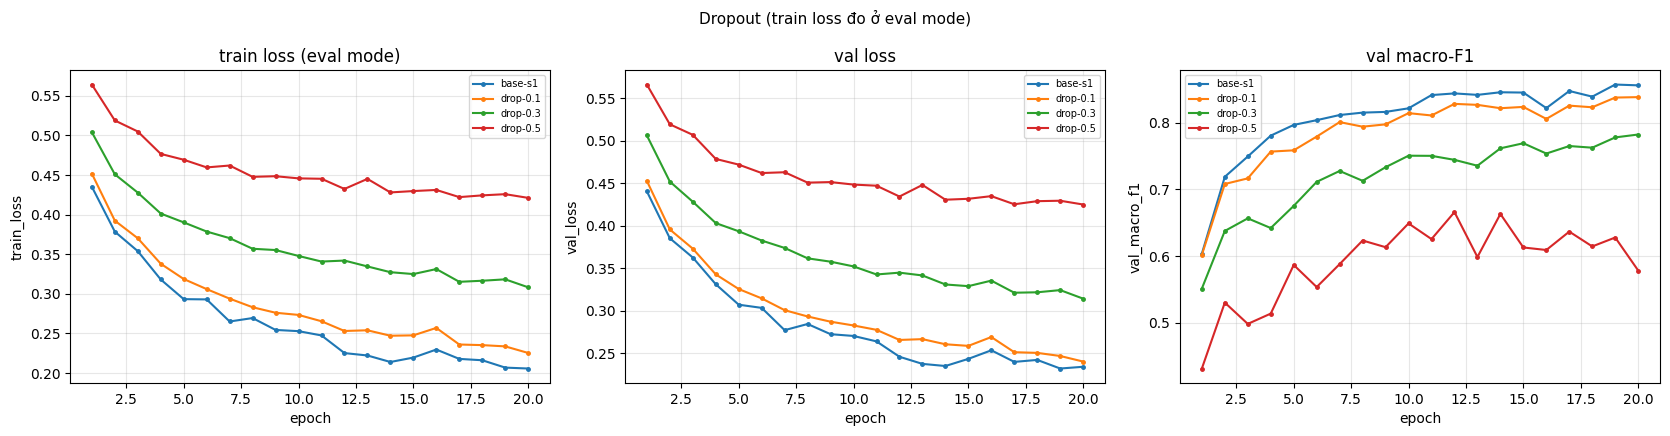

In [19]:
DROP_IDS = []
for q in [0.1, 0.3, 0.5]:
    eid = f'drop-{q:g}'
    run({**BASE, 'exp_id': eid, 'group': 'dropout', 'dropout': q,
         'description': f'dropout q={q:g} sau mỗi ReLU ẩn'})
    DROP_IDS.append(eid)
table(['base-s1'] + DROP_IDS)
plot_compare([RESULTS[e] for e in ['base-s1'] + DROP_IDS], ['train_loss', 'val_loss', 'val_macro_f1'],
             f'{OUT_DIR}/figures/compare_dropout.png', 'Dropout (train loss đo ở eval mode)')

**Đối chiếu sau khi chạy (dropout):** khớp dự đoán về hướng.
- Val macro-F1: q = 0,1 → **0,8385** (−0,022); q = 0,3 → 0,7824; q = 0,5 → 0,5784. Cả ba đều vượt 2σ. Dự đoán q = 0,1 "trong nhiễu" là sai: mức giảm vẫn rõ.
- Khoảng cách val − train (train đo ở eval mode) thu hẹp: 0,028 → 0,015 → 0,006 → 0,004. Dropout đúng là làm mất khoảng cách quá khớp, nhưng khoảng cách vốn đã rất nhỏ. Cái giá là train loss tăng (0,206 → 0,421 ở q = 0,5), tức càng thiếu khớp hơn.
- Macro-F1 giảm nhanh hơn acc nhiều (q = 0,5: acc 0,820 nhưng F1 0,578), nên lớp hiếm chịu thiệt nhất khi năng lực bị cắt.
- Cơ chế: dropout là chính quy hoá, giảm năng lực hiệu dụng và thêm nhiễu vào gradient. Mô hình này đang **thiếu khớp** nên dropout không có gì để chữa.

### Chủ đề 5 — Gradient clipping (`clip-*`)
Chọn `c` từ phân phối `grad_norm` (trước clip) của **base-s1**: `c` ≈ trung vị, để clipping thực sự kích hoạt ở khoảng một nửa số bước. Thí nghiệm phản chứng: lr ×10 và ×30 so với baseline, mỗi mức chạy **không clip** và **có clip c**.

**Dự đoán trước:** ở lr baseline gradient không có gai lớn, nên dù clip kích hoạt ở khoảng 50% số bước, kết quả gần như không đổi (trong 2σ). Ở lr cao, không clip thì loss dao động hoặc NaN. Có clip thì mỗi bước bị chặn `‖Δw‖ ≤ lr·c` (cộng thêm quán tính momentum), nên huấn luyện ổn định hơn hẳn, dù có thể vẫn kém baseline.

grad_norm của base-s1 trên mọi bước: p50=0.347  p90=0.406  p99=0.490  max=2.844
=> chọn c = 0.35
[clip-c0.35] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.4407  val 0.4443  acc 0.8090  F1 0.6112  |g| 0.459 (max 2.84)  1.17s
  ep  2  train 0.3750  val 0.3785  acc 0.8430  F1 0.7202  |g| 0.415 (max 0.67)  1.24s
  ep  3  train 0.3486  val 0.3583  acc 0.8484  F1 0.7520  |g| 0.396 (max 0.72)  1.27s
  ep  4  train 0.3145  val 0.3209  acc 0.8676  F1 0.7907  |g| 0.402 (max 0.79)  1.17s
  ep  5  train 0.2965  val 0.3074  acc 0.8738  F1 0.7917  |g| 0.391 (max 0.65)  1.26s
  ep  6  train 0.2811  val 0.2912  acc 0.8803  F1 0.8157  |g| 0.385 (max 0.59)  1.24s
  ep  7  train 0.2744  val 0.2862  acc 0.8824  F1 0.8185  |g| 0.379 (max 0.78)  1.40s
  ep  8  train 0.2589  val 0.2737  acc 0.8875  F1 0.8271  |g| 0.378 (max 0.60)  1.39s
  ep  9  train 0.2463  val 0.2631  acc 0.8932  F1 0.8306  |g| 0.374 (max 0.52)  1.28s
  ep 10  train 0.2503  val 0.2674  acc 0.8933  F1 0.8347  |g| 0.371 (max 0.6

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
clip-c0.35,sgd_momentum,0.3,512,19,2.2691,0.2287,0.0262,0.9089,0.8581,-0.0026,Không,1.2650,False
clip-lr10x-noclip,sgd_momentum,3.0,512,17,2.2691,1.2090,0.0018,0.4876,0.0936,-0.7671,Có,1.2454,False
clip-lr10x-c0.35,sgd_momentum,3.0,512,17,2.2691,0.9661,0.0046,0.5249,0.1928,-0.6679,Có,1.2778,False
clip-lr30x-noclip,sgd_momentum,9.0,512,1,2.2691,1.2172,0.0029,0.4876,0.0936,-0.7671,Có,1.2524,False
clip-lr30x-c0.35,sgd_momentum,9.0,512,2,2.2691,1.2156,-0.0006,0.4876,0.0936,-0.7671,Có,1.2635,False


tỉ lệ bước bị clip: {'clip-c0.35': 0.666, 'clip-lr10x-noclip': 0.0, 'clip-lr10x-c0.35': 0.033, 'clip-lr30x-noclip': 0.0, 'clip-lr30x-c0.35': 0.702}


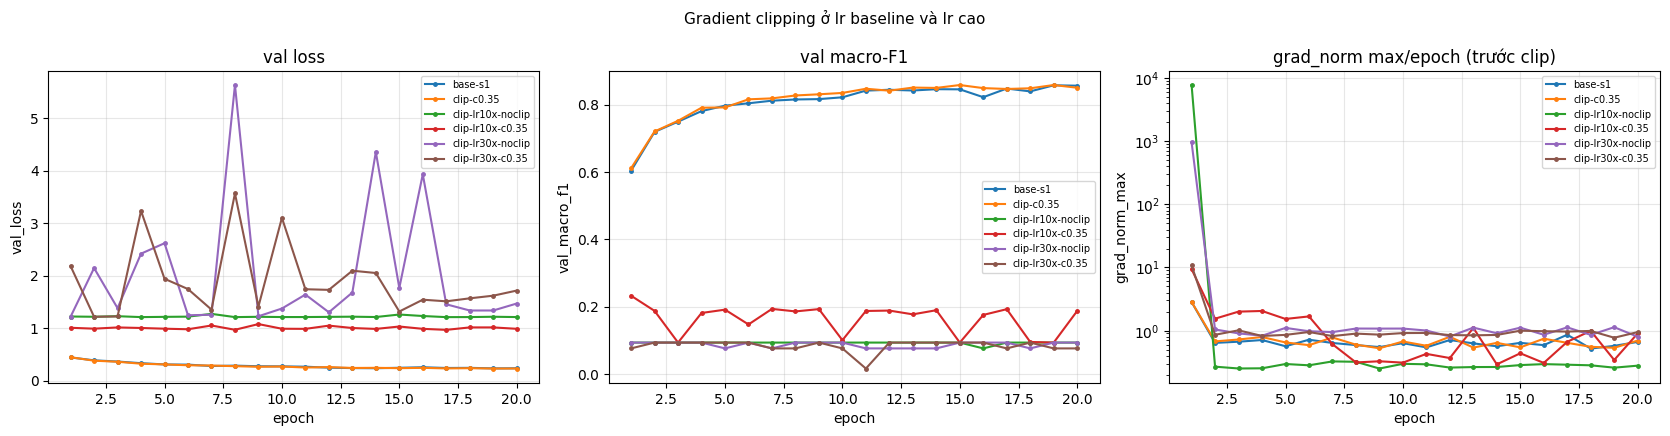

In [20]:
gs = RESULTS['base-s1']['summary']
print(f"grad_norm của base-s1 trên mọi bước: p50={gs['grad_norm_p50']:.3f}  p90={gs['grad_norm_p90']:.3f}  "
      f"p99={gs['grad_norm_p99']:.3f}  max={gs['grad_norm_max']:.3f}")
CLIP_C = float(f"{gs['grad_norm_p50']:.2g}")   # ≈ trung vị -> clip kích hoạt ở khoảng một nửa số bước
print('=> chọn c =', CLIP_C)
CLIP_IDS = [f'clip-c{CLIP_C:g}']
run({**BASE, 'exp_id': CLIP_IDS[0], 'group': 'clipping', 'clip_norm': CLIP_C,
     'description': f'clip c={CLIP_C:g} (≈ trung vị grad_norm của baseline), lr baseline'})
for mult in (10, 30):
    lr = mult * BASE_LR
    for clip in (None, CLIP_C):
        tag = 'noclip' if clip is None else f'c{CLIP_C:g}'
        eid = f'clip-lr{mult}x-{tag}'
        desc = f'lr = {mult} x baseline = {lr:g}, ' + ('không clip' if clip is None else f'clip c={CLIP_C:g}')
        note = ('phản chứng: chỉ đổi lr so với baseline' if clip is None
                else 'đổi 2 yếu tố (lr + clip) so với baseline; so với dòng noclip cùng lr')
        run({**BASE, 'exp_id': eid, 'group': 'clipping', 'lr': lr, 'clip_norm': clip,
             'description': desc, 'notes': note})
        CLIP_IDS.append(eid)
table(['base-s1'] + CLIP_IDS)
print('tỉ lệ bước bị clip:', {e: round(RESULTS[e]['summary']['clip_frac_overall'], 3) for e in CLIP_IDS})
plot_compare([RESULTS[e] for e in ['base-s1'] + CLIP_IDS], ['val_loss', 'val_macro_f1', 'grad_norm_max'],
             f'{OUT_DIR}/figures/compare_clipping.png', 'Gradient clipping ở lr baseline và lr cao')

**Đối chiếu sau khi chạy (clipping):** phần lr bình thường khớp dự đoán, phần lr cao **không khớp**.
- grad_norm của base-s1: p50 = 0,347, p90 = 0,406, p99 = 0,490, max = 2,84 (gai ở epoch 1). Chọn **c = 0,35**, clip kích hoạt ở **66,6%** số bước.
- `clip-c0.35`: 0,8581 so với TB baseline 0,8607 (−0,0026), **không vượt** 2σ. Ở lr bình thường, clipping chỉ co bước khoảng 10–20%, tương đương giảm nhẹ lr, nên không đổi kết quả.
- lr ×10 (3,0): không clip thì epoch 1 có gai grad_norm ≈ **7 800**, sau đó mạng sụp về đoán lớp đa số (val loss 1,209 = entropy phân bố lớp). Có clip thì đỡ hơn một chút (F1 0,193, val loss 0,966) nhưng **vẫn hỏng**. lr ×30 (9,0): cả hai đều hỏng, val loss dao động tới 5,6.
- **Vì sao clipping không cứu được:** clipping chặn ‖g‖ ≤ 0,35, nhưng với momentum 0,9, bước ổn định vẫn lên tới `lr·c/(1−μ)` = 3·0,35·10 ≈ **10,5** (chuẩn L2), lớn hơn nhiều so với độ lớn trọng số. Vài bước như vậy đủ đẩy pre-activation âm, ReLU chết, và gradient về ≈ 0 (nên tỉ lệ bước bị clip ở `clip-lr10x-c0.35` chỉ còn 3,3%). Clipping chữa được **gai hiếm**, không chữa được **lr quá lớn một cách hệ thống**. Muốn huấn luyện ở lr cao phải kết hợp warmup hoặc giảm lr.

### Chủ đề 6 — Mixed precision (`amp-*`)
FP16: `autocast(float16)` + `GradScaler` (unscale trước khi đo/clip gradient). BF16: `autocast(bfloat16)`, không GradScaler. Tham số vẫn là FP32. Thêm `amp-fp16-wide` để so với `hp-wide` (FP32), xem mixed precision có lợi hơn khi phép nhân ma trận lớn hơn không.

**Dự đoán trước:** mạng rất nhỏ (48k tham số, batch 512), nên thời gian mỗi bước bị chi phối bởi chi phí gọi kernel và Python, không phải FLOP. FP16 sẽ **không** nhanh hơn, thậm chí chậm hơn một chút vì thêm phép ép kiểu và GradScaler. Bộ nhớ đỉnh giảm nhẹ (kích hoạt FP16), độ chính xác gần như không đổi (trong 2σ). T4 không có phần cứng BF16 nên BF16 có thể chậm hơn FP32. Với M-wide, FP16 có thể đỡ chậm hơn nhưng vẫn khó nhanh hơn rõ.

Vì sao FP16 cần nhân loss với hệ số `s`: FP16 chỉ có 5 bit mũ (giá trị dương nhỏ nhất ~6e-8, lớn nhất 65504), nên gradient nhỏ dễ bị làm tròn về 0 (underflow). BF16 có 8 bit mũ như FP32 (dải ~1e-38 đến 3e38), chỉ ít bit định trị hơn, nên thường không cần scale.

[amp-fp16] step0 val loss = 2.2691  (ln7 = 1.9459)
  ep  1  train 0.4347  val 0.4378  acc 0.8138  F1 0.6068  |g| 0.378 (max 2.84)  2.06s
  ep  2  train 0.3769  val 0.3794  acc 0.8402  F1 0.7306  |g| 0.368 (max 0.58)  1.64s
  ep  3  train 0.3560  val 0.3610  acc 0.8484  F1 0.7382  |g| 0.366 (max 0.62)  1.66s
  ep  4  train 0.3163  val 0.3263  acc 0.8655  F1 0.7854  |g| 0.367 (max 0.65)  1.68s
  ep  5  train 0.3096  val 0.3223  acc 0.8663  F1 0.7866  |g| 0.355 (max 0.60)  1.71s
  ep  6  train 0.2727  val 0.2863  acc 0.8822  F1 0.8149  |g| 0.356 (max 0.62)  1.65s
  ep  7  train 0.2680  val 0.2758  acc 0.8875  F1 0.8173  |g| 0.353 (max 0.64)  1.88s
  ep  8  train 0.2695  val 0.2863  acc 0.8840  F1 0.8220  |g| 0.351 (max 0.70)  1.95s
  ep  9  train 0.2487  val 0.2613  acc 0.8955  F1 0.8272  |g| 0.354 (max 0.52)  1.68s
  ep 10  train 0.2457  val 0.2672  acc 0.8945  F1 0.8269  |g| 0.347 (max 0.58)  1.74s
  ep 11  train 0.2367  val 0.2535  acc 0.8976  F1 0.8331  |g| 0.342 (max 0.54)  1.69s
  e

,precision,hidden,s_per_epoch,peak_mem_MB,val_acc,val_macro_f1
exp_id,,,,,,
base-s1,fp32,256-128,1.2549,28.8457,0.9090,0.8573
hp-wide,fp32,512-256,1.2575,46.1436,0.9226,0.8747
amp-fp16,fp16,256-128,1.7355,28.8447,0.9112,0.8597
amp-bf16,bf16,256-128,1.5446,28.8438,0.9102,0.8520
amp-fp16-wide,fp16,512-256,1.7253,46.1426,0.9247,0.8745


,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
amp-fp16,sgd_momentum,0.3,512,15,2.2691,0.2220,0.0230,0.9112,0.8597,-0.0010,Không,1.7355,False
amp-bf16,sgd_momentum,0.3,512,20,2.2691,0.2250,0.0229,0.9102,0.8520,-0.0087,Có,1.5446,False
amp-fp16-wide,sgd_momentum,0.3,512,20,1.9182,0.1941,0.0319,0.9247,0.8745,0.0138,Có,1.7253,False


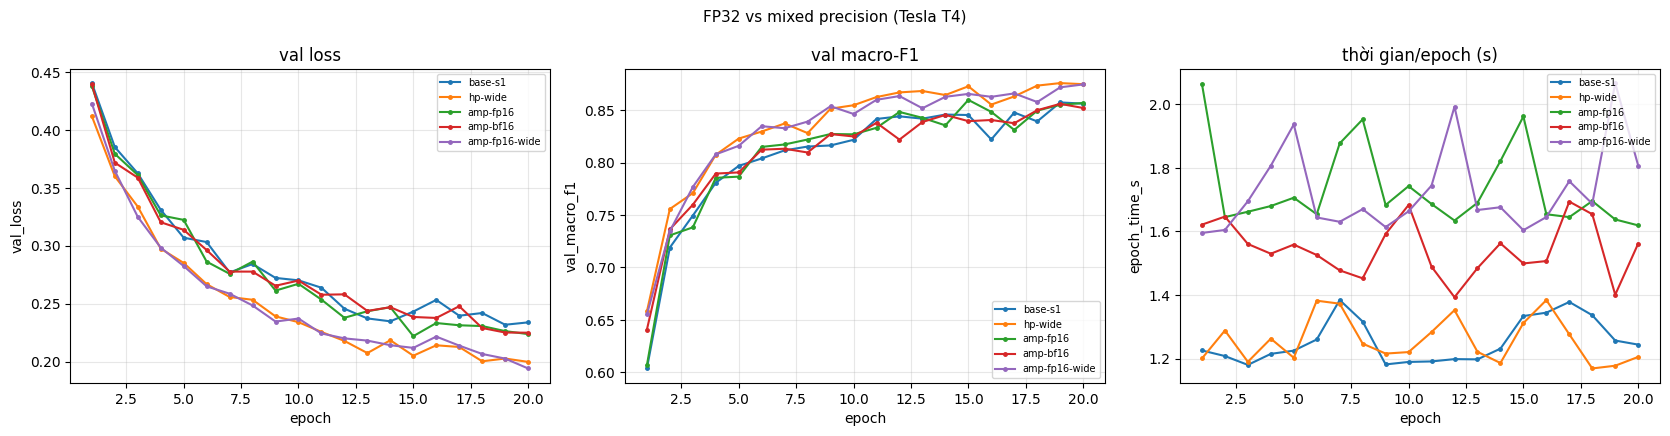

In [21]:
AMP_IDS = []
for prec in ('fp16', 'bf16'):
    eid = f'amp-{prec}'
    if prec == 'bf16' and device.type == 'cuda' and not torch.cuda.is_bf16_supported():
        print('GPU không hỗ trợ bf16 -> bỏ qua amp-bf16')
        continue
    tool = 'autocast + GradScaler' if prec == 'fp16' else 'autocast, không GradScaler'
    try:
        run({**BASE, 'exp_id': eid, 'group': 'amp', 'precision': prec,
             'description': f'mixed precision {prec} ({tool})', 'notes': f'thiết bị: {GPU_NAME}'})
        AMP_IDS.append(eid)
    except Exception as ex:
        print(f'{eid} không chạy được trên {GPU_NAME}: {ex}')
run({**BASE, 'exp_id': 'amp-fp16-wide', 'group': 'amp', 'precision': 'fp16', 'hidden': (512, 256),
     'description': 'M-wide + fp16 (so với hp-wide fp32)',
     'notes': f'đổi 2 yếu tố so với baseline; so sánh với hp-wide; thiết bị: {GPU_NAME}'})
AMP_IDS.append('amp-fp16-wide')
amp_tab = pd.DataFrame([dict(exp_id=e, precision=RESULTS[e]['cfg']['precision'],
                             hidden='-'.join(map(str, RESULTS[e]['cfg']['hidden'])),
                             s_per_epoch=f(RESULTS[e]['summary']['time_per_epoch_s']),
                             peak_mem_MB=f(RESULTS[e]['summary']['peak_mem_MB']),
                             val_acc=f(RESULTS[e]['summary']['val_acc']),
                             val_macro_f1=f(RESULTS[e]['summary']['val_macro_f1']))
                        for e in ['base-s1', 'hp-wide'] + AMP_IDS]).set_index('exp_id')
display(amp_tab.round(4))
table(['base-s1'] + AMP_IDS)
plot_compare([RESULTS[e] for e in ['base-s1', 'hp-wide'] + AMP_IDS], ['val_loss', 'val_macro_f1', 'epoch_time_s'],
             f'{OUT_DIR}/figures/compare_amp.png', f'FP32 vs mixed precision ({GPU_NAME})')

**Đối chiếu sau khi chạy (mixed precision, Tesla T4):** khớp dự đoán.
- Thời gian/epoch: FP32 **1,255 s** · FP16 **1,736 s (+38%)** · BF16 1,545 s (+23%). M-wide: FP32 1,257 s · FP16 1,725 s. **Mixed precision chậm hơn**, kể cả với M-wide.
- Bộ nhớ đỉnh gần như không đổi (28,8 MB; M-wide 46,1 MB): kích hoạt của một lô 512×256 chỉ khoảng 0,5 MB, còn đỉnh bộ nhớ bị chi phối bởi bước đánh giá (lô 8 192, FP32) và tập con train 50k mẫu.
- Độ chính xác: FP16 0,8597 (trong 2σ); M-wide FP16 0,8745 ≈ FP32 0,8747. BF16 0,8520 (−0,0087, vừa vượt 2σ; 1 seed, BF16 chỉ có 8 bit định trị) nên chưa đủ bằng chứng là BF16 kém hơn.
- Cơ chế: mỗi bước nhân ma trận chỉ vài MFLOP, trong khi Tensor Core FP16 của T4 xử lý cỡ chục TFLOP/s, nên thời gian thực chủ yếu là **chi phí gọi kernel và Python**. Autocast thêm các kernel ép kiểu; GradScaler thêm unscale, kiểm tra inf và update. Nhiều lần gọi kernel hơn nên chậm hơn. T4 không có phần cứng BF16, phép BF16 chạy giả lập.

### Chủ đề 7 — Khởi tạo tham số (`init-*`)
`zeros` (W = 0), `normal` (W ~ N(0, 0.01²)), `xavier` (`xavier_normal_`, Var = 2/(n_in+n_out), công thức của PyTorch), `default` (mặc định `nn.Linear`: Kaiming-uniform a=√5, Var ≈ 1/(3·n_in), **không** phải He); baseline là `he` (Var = 2/n_in). Bias = 0 cho mọi cách trừ `default`.

**Dự đoán trước:**
- `zeros`: mọi kích hoạt ẩn bằng ReLU(0) = 0, nên gradient tới W1, W2, W3 đều bằng 0 (đối xứng hoàn toàn và tín hiệu không đi qua được). Chỉ bias lớp ra học được, nên mô hình chỉ học được tần suất lớp: acc ≈ 0,4876, macro-F1 ≈ 0,09, loss bước 0 = ln 7 chính xác.
- `normal` 0,01: std kích hoạt giảm khoảng 10 lần mỗi lớp, logit gần 0, loss bước 0 ≈ ln 7. Gradient của lớp đầu rất nhỏ nên học chậm ở các epoch đầu, nhưng mạng chỉ 3 lớp nên vẫn học được, có thể hơi kém baseline.
- `xavier`, `default`: với mạng nông, khác He không đáng kể (trong 2σ). Std kích hoạt nhỏ hơn He một chút.
- Mạng 3 lớp quá nông để thấy rõ hiện tượng "30 lớp ReLU" của slide, nên mình thêm một phép đo forward trên mạng 30 lớp (không huấn luyện).

[init-zeros] step0 val loss = 1.9459  (ln7 = 1.9459)
  ep  1  train 1.2049  val 1.2066  acc 0.4876  F1 0.0936  |g| 0.044 (max 0.50)  1.29s
  ep  2  train 1.2055  val 1.2076  acc 0.4876  F1 0.0936  |g| 0.038 (max 0.12)  1.19s
  ep  3  train 1.2034  val 1.2053  acc 0.4876  F1 0.0936  |g| 0.040 (max 0.13)  1.25s
  ep  4  train 1.2040  val 1.2056  acc 0.4876  F1 0.0936  |g| 0.037 (max 0.16)  1.20s
  ep  5  train 1.2039  val 1.2058  acc 0.4876  F1 0.0936  |g| 0.038 (max 0.13)  1.24s
  ep  6  train 1.2044  val 1.2063  acc 0.4876  F1 0.0936  |g| 0.038 (max 0.12)  1.37s
  ep  7  train 1.2042  val 1.2059  acc 0.4876  F1 0.0936  |g| 0.038 (max 0.12)  1.39s
  ep  8  train 1.2044  val 1.2062  acc 0.4876  F1 0.0936  |g| 0.036 (max 0.13)  1.26s
  ep  9  train 1.2039  val 1.2056  acc 0.4876  F1 0.0936  |g| 0.038 (max 0.12)  1.18s
  ep 10  train 1.2045  val 1.2063  acc 0.4876  F1 0.0936  |g| 0.037 (max 0.12)  1.21s
  ep 11  train 1.2042  val 1.2060  acc 0.4876  F1 0.0936  |g| 0.036 (max 0.12)  1.23s
 

,std ReLU1,std ReLU2,std logits,step0_loss
base-s1,0.39012,0.36613,0.57728,2.26906
init-zeros,0.00000,0.00000,0.00000,1.94591
init-normal,0.02027,0.00215,0.00027,1.94600
init-xavier,0.16282,0.12477,0.19156,2.02218
init-default,0.16028,0.06776,0.05851,1.98304


,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.3,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
init-zeros,sgd_momentum,0.3,512,16,1.9459,1.2053,0.0017,0.4876,0.0936,-0.7671,Có,1.2624,False
init-normal,sgd_momentum,0.3,512,20,1.9460,0.2204,0.0269,0.9137,0.8609,0.0002,Không,1.2642,False
init-xavier,sgd_momentum,0.3,512,18,2.0222,0.2236,0.0269,0.9096,0.8502,-0.0105,Có,1.2435,False
init-default,sgd_momentum,0.3,512,20,1.9830,0.2170,0.0281,0.9145,0.8637,0.0029,Không,1.2473,False


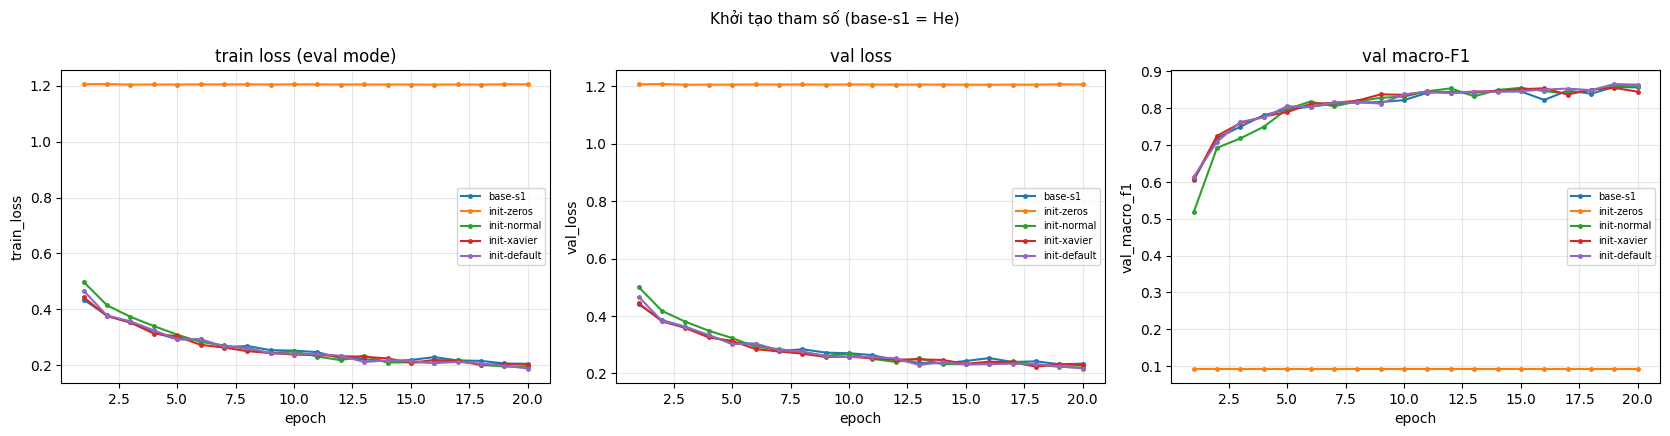

In [22]:
INIT_DESC = {'zeros': 'W = 0, bias = 0', 'normal': 'W ~ N(0, 0.01^2), bias = 0',
             'xavier': 'xavier_normal_ (Var = 2/(n_in+n_out)), bias = 0',
             'default': 'mặc định nn.Linear (Kaiming-uniform a=sqrt5), KHÔNG phải He'}
INIT_IDS = []
for init, desc in INIT_DESC.items():
    eid = f'init-{init}'
    run({**BASE, 'exp_id': eid, 'group': 'init', 'init': init, 'description': f'khởi tạo {desc}'})
    INIT_IDS.append(eid)
act = pd.DataFrame({e: RESULTS[e]['summary']['act_std_step0'] for e in ['base-s1'] + INIT_IDS},
                   index=['std ReLU1', 'std ReLU2', 'std logits']).T
act['step0_loss'] = [f(RESULTS[e]['summary']['step0_loss']) for e in act.index]
print('Độ lệch chuẩn kích hoạt ở bước 0 (một lô val 4096 mẫu); base-s1 = He:')
display(act.round(5))
table(['base-s1'] + INIT_IDS)
plot_compare([RESULTS[e] for e in ['base-s1'] + INIT_IDS], ['train_loss', 'val_loss', 'val_macro_f1'],
             f'{OUT_DIR}/figures/compare_init.png', 'Khởi tạo tham số (base-s1 = He)')

normal   std sau ReLU lớp 1 = 2.080e-02, lớp 30 = 0.000e+00
xavier   std sau ReLU lớp 1 = 1.671e-01, lớp 30 = 4.793e-06
default  std sau ReLU lớp 1 = 1.668e-01, lớp 30 = 2.353e-02
he       std sau ReLU lớp 1 = 4.003e-01, lớp 30 = 2.661e-01


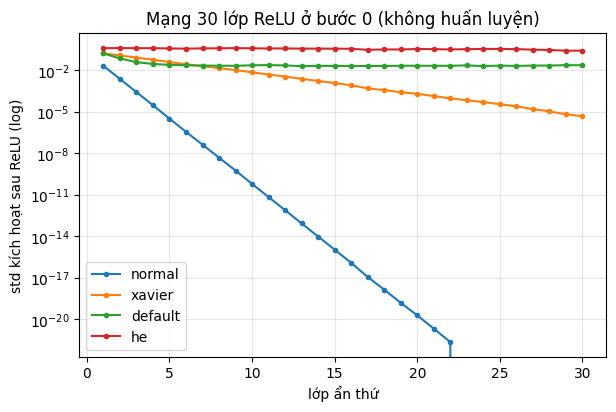

In [23]:
# Bổ sung (không phải một dòng thí nghiệm): std kích hoạt qua mạng 30 lớp ReLU (256 nơ-ron/lớp) ở bước 0
x4k = data['X_val'][:4096]
plt.figure(figsize=(6.8, 4.2))
for init in ('normal', 'xavier', 'default', 'he'):
    set_seed(0)
    net = MLP(tuple([256] * 30), 0.0, init).to(device)
    stds = activation_stats(net, x4k)[:-1]
    plt.semilogy(range(1, 31), stds, 'o-', ms=3, label=init)
    print(f'{init:8s} std sau ReLU lớp 1 = {stds[0]:.3e}, lớp 30 = {stds[-1]:.3e}')
plt.xlabel('lớp ẩn thứ')
plt.ylabel('std kích hoạt sau ReLU (log)')
plt.title('Mạng 30 lớp ReLU ở bước 0 (không huấn luyện)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f'{OUT_DIR}/figures/compare_init_depth30.png', dpi=110, bbox_inches='tight')
plt.show()

**Đối chiếu sau khi chạy (khởi tạo):**
- `zeros`: loss bước 0 = **1,9459** (= ln 7), std kích hoạt = 0. Mạng chỉ học được bias lớp ra: acc 0,4876, macro-F1 0,0936, val loss 1,205 (= entropy phân bố lớp). **Khớp dự đoán.** Mọi nơ-ron có cùng (bằng 0) gradient, đối xứng không bao giờ bị phá.
- `normal` (0,01): std kích hoạt 0,020 → 0,002 → 0,0003 (giảm khoảng 10 lần mỗi lớp), loss bước 0 = 1,9460. Nhưng kết quả cuối **0,8609 ≈ baseline** (trong nhiễu). **Khác dự đoán** "hơi kém": mạng chỉ 3 lớp, và với lr 0,3 + momentum, trọng số được kéo về thang hợp lý ngay trong epoch đầu.
- `xavier`: 0,8502 (−0,0105, vượt 2σ, 1 seed); std kích hoạt khoảng 0,16, chỉ bằng 0,4 lần của He. `default`: 0,8637 (+0,003, trong nhiễu). Với mạng nông, khác biệt giữa xavier, default và he nhỏ.
- **Mạng 30 lớp** (ảnh `compare_init_depth30.png`): std sau ReLU ở lớp 30 là he 0,27 (gần như giữ nguyên), default 0,024, xavier **4,8e-6**, normal **0** (underflow). Xavier giảm khoảng 2 lần mỗi lớp vì Var = 2/(n_in+n_out) = 1/n_in, nhưng ReLU làm mất một nửa phương sai; He bù lại đúng hệ số 2. `default` không tắt hẳn là nhờ bias khác 0 (uniform ±1/√n_in) của `nn.Linear`. Kết quả này đúng với biểu đồ "30 lớp ReLU" trong slide.

### Cấu hình cuối cùng (`fin-*`) — chọn hoàn toàn bằng val
Quy trình (định sẵn trước khi xem bất kỳ số eval nào):
1. Lấy bộ tối ưu + lr + weight decay có **val macro-F1 cao nhất** trong chủ đề optimizer (kể cả baseline).
2. Kết hợp với mô hình lớn hơn và huấn luyện 40 epoch (baseline chưa hội tụ ở epoch 20). Ba ứng viên (seed 1): `M-wide`, `M-deep`, `M-wide` + cosine lr.
3. Chọn ứng viên có val macro-F1 cao nhất, chạy thêm seed 2, 3 để đo nhiễu. **Nộp mô hình seed 1** (định trước, không chọn seed theo eval), dùng trọng số ở epoch có val loss thấp nhất.

**Dự đoán trước:** cấu hình cuối hơn baseline ≥ 0,02 val macro-F1 (vượt 2σ), nhờ năng lực lớn hơn, nhiều bước hơn và bộ tối ưu tốt hơn.

bộ tối ưu tốt nhất theo val: opt-adam-lr0.003 -> adam, lr=0.003, wd=0
[fin-wide-e40-s1] step0 val loss = 1.9182  (ln7 = 1.9459)
  ep  1  train 0.4096  val 0.4135  acc 0.8237  F1 0.6773  |g| 0.668 (max 3.28)  1.58s
  ep  2  train 0.3308  val 0.3376  acc 0.8597  F1 0.7673  |g| 0.617 (max 1.53)  1.55s
  ep  3  train 0.3067  val 0.3153  acc 0.8676  F1 0.8026  |g| 0.595 (max 1.34)  1.34s
  ep  4  train 0.2615  val 0.2752  acc 0.8876  F1 0.8292  |g| 0.584 (max 1.58)  1.42s
  ep  5  train 0.2403  val 0.2565  acc 0.8958  F1 0.8462  |g| 0.572 (max 1.21)  1.36s
  ep  6  train 0.2280  val 0.2459  acc 0.8998  F1 0.8472  |g| 0.567 (max 1.39)  1.36s
  ep  7  train 0.2088  val 0.2268  acc 0.9067  F1 0.8605  |g| 0.548 (max 1.09)  1.45s
  ep  8  train 0.1980  val 0.2200  acc 0.9115  F1 0.8661  |g| 0.556 (max 1.18)  1.38s
  ep  9  train 0.1946  val 0.2165  acc 0.9127  F1 0.8721  |g| 0.543 (max 1.27)  1.55s
  ep 10  train 0.1907  val 0.2155  acc 0.9151  F1 0.8689  |g| 0.541 (max 1.21)  1.69s
  ep 11  tra

,opt,lr,batch,best_epoch,step0_loss,best_val_loss,gap_val_train,val_acc,val_macro_f1,dF1_vs_base,beyond_2sigma,s_per_epoch,diverged
exp_id,,,,,,,,,,,,,
base-s1,sgd_momentum,0.300,512,19,2.2691,0.2318,0.0282,0.9090,0.8573,-0.0034,Không,1.2549,False
fin-wide-e40-s1,adam,0.003,512,33,1.9182,0.1578,0.0477,0.9402,0.9052,0.0445,Có,1.4270,False
fin-deep-e40-s1,adam,0.003,512,38,1.9099,0.1641,0.0443,0.9370,0.8946,0.0339,Có,1.6216,False
fin-wide-cos-e40-s1,adam,0.003,512,39,1.9182,0.1231,0.0535,0.9541,0.9267,0.0660,Có,1.4480,False


=> CẤU HÌNH CUỐI (theo val macro-F1): fin-wide-cos-e40-s1
[fin-wide-cos-e40-s2] step0 val loss = 2.6520  (ln7 = 1.9459)
  ep  1  train 0.4050  val 0.4101  acc 0.8257  F1 0.7107  |g| 0.691 (max 4.68)  1.41s
  ep  2  train 0.3276  val 0.3362  acc 0.8621  F1 0.7756  |g| 0.641 (max 1.59)  1.48s
  ep  3  train 0.2990  val 0.3058  acc 0.8745  F1 0.8131  |g| 0.619 (max 1.68)  1.74s
  ep  4  train 0.2779  val 0.2932  acc 0.8785  F1 0.8139  |g| 0.639 (max 1.60)  1.57s
  ep  5  train 0.2482  val 0.2645  acc 0.8925  F1 0.8336  |g| 0.614 (max 1.58)  1.46s
  ep  6  train 0.2375  val 0.2563  acc 0.8961  F1 0.8299  |g| 0.611 (max 1.69)  1.38s
  ep  7  train 0.2112  val 0.2309  acc 0.9063  F1 0.8529  |g| 0.613 (max 1.47)  1.40s
  ep  8  train 0.1975  val 0.2229  acc 0.9113  F1 0.8552  |g| 0.589 (max 1.58)  1.42s
  ep  9  train 0.2041  val 0.2253  acc 0.9103  F1 0.8596  |g| 0.604 (max 1.19)  1.40s
  ep 10  train 0.1908  val 0.2120  acc 0.9140  F1 0.8674  |g| 0.596 (max 1.25)  1.34s
  ep 11  train 0.177

,val_acc,val_macro_f1
fin-wide-cos-e40-s1,0.9541,0.9267
fin-wide-cos-e40-s2,0.9532,0.9254
fin-wide-cos-e40-s3,0.9536,0.9272
mean,0.9537,0.9264
std,0.0004,0.0010


cấu hình cuối: val macro-F1 = 0.9264 ± 0.0010  vs baseline 0.8607 ± 0.0030


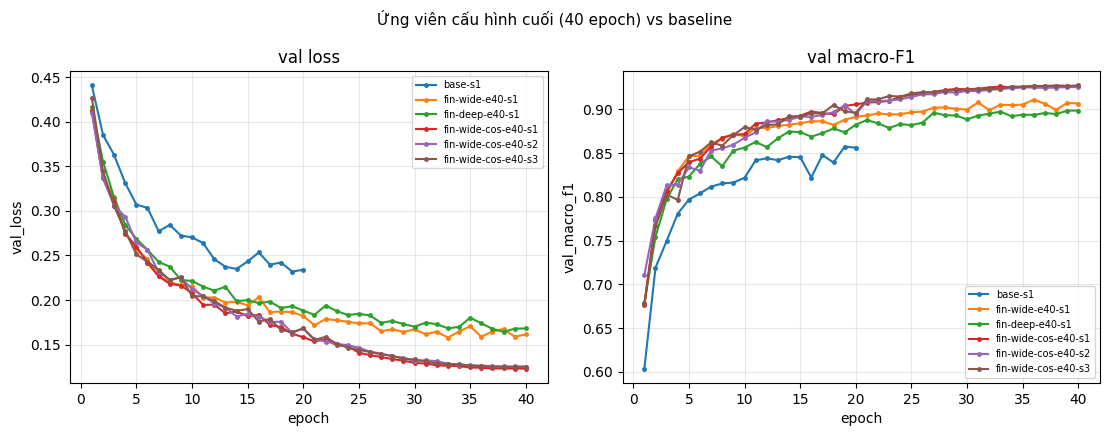

In [24]:
cand_opt = ['base-s1'] + [e for e in RESULTS if RESULTS[e]['cfg']['group'] == 'optimizer']
BEST_OPT_ID = best_of(cand_opt)
bo = RESULTS[BEST_OPT_ID]['cfg']
print(f"bộ tối ưu tốt nhất theo val: {BEST_OPT_ID} -> {bo['optimizer']}, lr={bo['lr']:g}, wd={bo['weight_decay']:g}")
FIN = {**BASE, 'group': 'final', 'optimizer': bo['optimizer'], 'lr': bo['lr'],
       'weight_decay': bo['weight_decay'], 'epochs': 40}
opt_txt = f"{bo['optimizer']} lr={bo['lr']:g}"
FIN_CANDS = [
    dict(exp_id='fin-wide-e40-s1', hidden=(512, 256), description=f'M-wide + {opt_txt}, 40 epoch'),
    dict(exp_id='fin-deep-e40-s1', hidden=(256, 128, 64), description=f'M-deep + {opt_txt}, 40 epoch'),
    dict(exp_id='fin-wide-cos-e40-s1', hidden=(512, 256), scheduler='cosine',
         description=f'M-wide + {opt_txt} + cosine lr, 40 epoch'),
]
for c in FIN_CANDS:
    run({**FIN, **c, 'notes': 'ứng viên cấu hình cuối (kết hợp nhiều yếu tố); chọn bằng val'}, save_ckpt=True)
FIN_IDS = [c['exp_id'] for c in FIN_CANDS]
table(['base-s1'] + FIN_IDS)
FINAL_ID = best_of(FIN_IDS)
final_cfg = RESULTS[FINAL_ID]['cfg']
print('=> CẤU HÌNH CUỐI (theo val macro-F1):', FINAL_ID)

# độ nhiễu seed của cấu hình cuối (seed 2, 3); mô hình nộp vẫn là seed 1
stem = FINAL_ID[:-3]
FINAL_SEED_IDS = [FINAL_ID]
for s in (2, 3):
    eid = f'{stem}-s{s}'
    run({**final_cfg, 'exp_id': eid, 'seed': s, 'description': final_cfg['description'] + f' (seed {s})',
         'notes': 'đo nhiễu seed của cấu hình cuối; không dùng để nộp'})
    FINAL_SEED_IDS.append(eid)
fs = pd.DataFrame([{k: f(RESULTS[e]['summary'][k]) for k in ('val_acc', 'val_macro_f1')} for e in FINAL_SEED_IDS],
                  index=FINAL_SEED_IDS)
display(pd.concat([fs, fs.agg(['mean', 'std'])]).round(4))
fin_m, fin_s = fs['val_macro_f1'].mean(), fs['val_macro_f1'].std()
print(f'cấu hình cuối: val macro-F1 = {fin_m:.4f} ± {fin_s:.4f}  vs baseline {BASE_F1_MEAN:.4f} ± {BASE_F1_STD:.4f}')
plot_compare([RESULTS[e] for e in ['base-s1'] + FIN_IDS + FINAL_SEED_IDS[1:]], ['val_loss', 'val_macro_f1'],
             f'{OUT_DIR}/figures/compare_final.png', 'Ứng viên cấu hình cuối (40 epoch) vs baseline')

## Part 4 — Đánh giá cuối trên eval, bảng và nộp bài
Đến đây cấu hình cuối đã được chốt **chỉ bằng val**. Dự đoán trên **toàn bộ** eval ở `eval()` (không dropout), với trọng số ở epoch có val loss thấp nhất, rồi chấm bằng đúng `scripts/evaluate.py`. Chỉ làm cho baseline (`base-s1`) và cấu hình cuối; **không chỉnh lại gì sau bước này**.

In [25]:
# Baseline (base-s1): dự đoán lưu trong results/ (không phải file nộp chính)
base_pred = f'{OUT_DIR}/results/predictions_eval_base-s1.csv'
final_eval(RESULTS['base-s1']['cfg'], RESULTS['base-s1'], data, base_pred)
EVAL_BASE = run_evaluate_script(REPO_ROOT, base_pred, f'{OUT_DIR}/results/eval_result_base-s1.json')

# Cấu hình cuối (seed 1): file nộp chính
final_eval(final_cfg, RESULTS[FINAL_ID], data, f'{OUT_DIR}/predictions_eval.csv')
EVAL_FINAL = run_evaluate_script(REPO_ROOT, f'{OUT_DIR}/predictions_eval.csv', f'{OUT_DIR}/eval_result.json')

summary_eval = pd.DataFrame([
    dict(config='baseline', exp_id='base-s1', val_macro_f1=f(RESULTS['base-s1']['summary']['val_macro_f1']),
         eval_macro_f1=EVAL_BASE['macro_f1'], eval_acc=EVAL_BASE['accuracy']),
    dict(config='final', exp_id=FINAL_ID, val_macro_f1=f(RESULTS[FINAL_ID]['summary']['val_macro_f1']),
         eval_macro_f1=EVAL_FINAL['macro_f1'], eval_acc=EVAL_FINAL['accuracy']),
]).set_index('config')
display(summary_eval.round(4))
print(f"cải thiện eval macro-F1 (cuối - baseline) = {EVAL_FINAL['macro_f1'] - EVAL_BASE['macro_f1']:+.4f}")

đã ghi ../results/predictions_eval_base-s1.csv (116203 dòng)
n_eval = 116203
accuracy = 0.9089
macro_f1 = 0.8565   <- chỉ số chính

lớp  support  precision  recall    f1
  0    42368     0.9304  0.8798  0.9044
  1    56661     0.9025  0.9514  0.9263
  2     7151     0.9303  0.8610  0.8943
  3      549     0.8330  0.7723  0.8015
  4     1899     0.8195  0.7077  0.7595
  5     3473     0.7670  0.8557  0.8089
  6     4102     0.9405  0.8632  0.9002

ma trận nhầm lẫn (hàng = thật, cột = dự đoán):
       0      1     2    3     4     5     6
0  37274   4837     1    0    44     9   203
1   2225  53908    87    0   237   183    21
2     13    271  6157   67    14   629     0
3      0      0    57  424     0    68     0
4     26    494    21    0  1344    14     0
5     17    170   295   18     1  2972     0
6    506     55     0    0     0     0  3541

đã ghi /content/K4-Track4-Day1-Neuralnetwork/submission_2A202602798/results/eval_result_base-s1.json

đã ghi ../predictions_eval.csv (116203 

,exp_id,val_macro_f1,eval_macro_f1,eval_acc
config,,,,
baseline,base-s1,0.8573,0.8565,0.9089
final,fin-wide-cos-e40-s1,0.9267,0.9294,0.9531


cải thiện eval macro-F1 (cuối - baseline) = +0.0730


,name,support,precision,recall,f1,f1_baseline,n_train
cls,,,,,,,
0,0 Spruce/Fir,42368,0.9524,0.9472,0.9498,0.9044,135578
1,1 Lodgepole Pine,56661,0.9573,0.9632,0.9602,0.9263,181312
2,2 Ponderosa Pine,7151,0.9539,0.9547,0.9543,0.8943,22882
3,3 Cottonwood/Willow,549,0.8969,0.8561,0.8760,0.8015,1759
4,4 Aspen,1899,0.9086,0.8794,0.8938,0.7595,6075
5,5 Douglas-fir,3473,0.9200,0.9110,0.9155,0.8089,11115
6,6 Krummholz,4102,0.9570,0.9559,0.9565,0.9002,13126


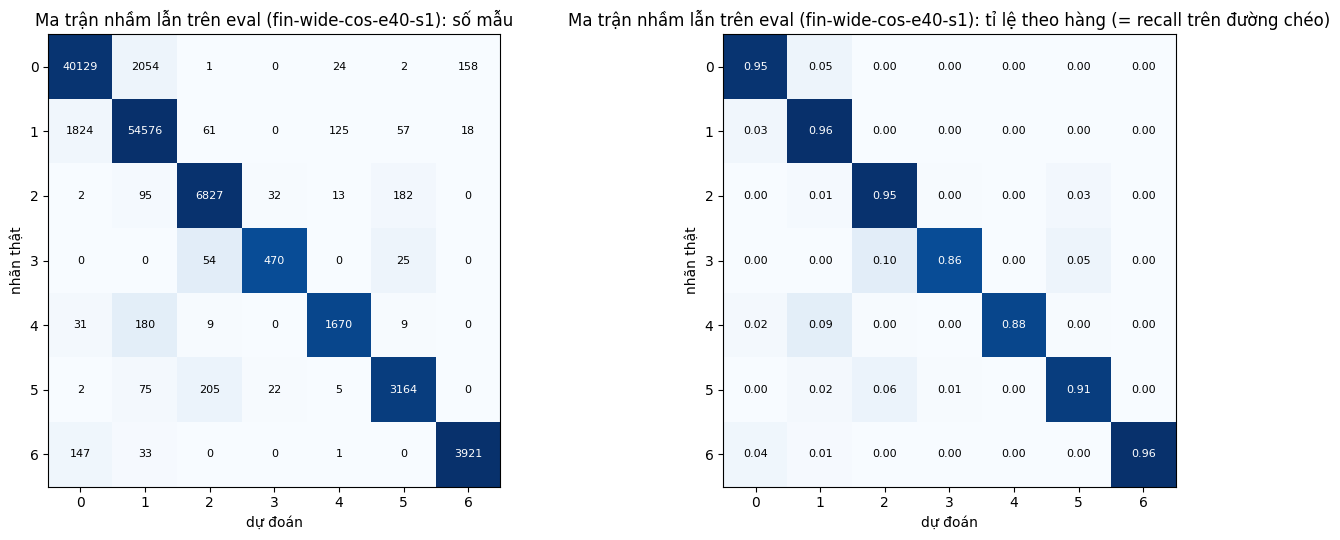

lớp 0 Spruce/Fir           recall 0.947; nhầm nhiều nhất sang 1 Lodgepole Pine (4.8%)
lớp 1 Lodgepole Pine       recall 0.963; nhầm nhiều nhất sang 0 Spruce/Fir (3.2%)
lớp 2 Ponderosa Pine       recall 0.955; nhầm nhiều nhất sang 5 Douglas-fir (2.5%)
lớp 3 Cottonwood/Willow    recall 0.856; nhầm nhiều nhất sang 2 Ponderosa Pine (9.8%)
lớp 4 Aspen                recall 0.879; nhầm nhiều nhất sang 1 Lodgepole Pine (9.5%)
lớp 5 Douglas-fir          recall 0.911; nhầm nhiều nhất sang 2 Ponderosa Pine (5.9%)
lớp 6 Krummholz            recall 0.956; nhầm nhiều nhất sang 0 Spruce/Fir (3.6%)
=> lớp khó nhất (F1 thấp nhất): 3 Cottonwood/Willow F1 = 0.876


In [26]:
# Phân tích lỗi theo lớp trên eval (từ eval_result.json do evaluate.py tạo)
pc = pd.DataFrame(EVAL_FINAL['per_class']).set_index('cls')
pc.insert(0, 'name', CLASS_NAMES)
pc['f1_baseline'] = pd.DataFrame(EVAL_BASE['per_class']).set_index('cls')['f1']
pc['n_train'] = np.bincount(data['y_tr'].cpu().numpy(), minlength=7)
display(pc.round(4))
cm = np.array(EVAL_FINAL['confusion_matrix'])
cmn = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, M, ttl, fmt in ((axes[0], cm, 'số mẫu', 'd'), (axes[1], cmn, 'tỉ lệ theo hàng (= recall trên đường chéo)', '.2f')):
    ax.imshow(cmn, cmap='Blues')
    for i in range(7):
        for j in range(7):
            ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', fontsize=8,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    ax.set_xlabel('dự đoán')
    ax.set_ylabel('nhãn thật')
    ax.set_title(f'Ma trận nhầm lẫn trên eval ({FINAL_ID}): {ttl}')
plt.tight_layout()
plt.show()
for c in range(7):
    row = cmn[c].copy()
    row[c] = 0
    j = int(row.argmax())
    print(f'lớp {CLASS_NAMES[c]:22s} recall {cmn[c, c]:.3f}; nhầm nhiều nhất sang {CLASS_NAMES[j]} ({row[j]:.1%})')
hardest = int(pc['f1'].idxmin())
print('=> lớp khó nhất (F1 thấp nhất):', CLASS_NAMES[hardest], 'F1 =', round(pc.loc[hardest, 'f1'], 4))

**Phân tích lỗi (eval, cấu hình cuối `fin-wide-cos-e40-s1`):**
- Lớp khó nhất: **lớp 3 Cottonwood/Willow, F1 = 0,876** (precision 0,897, recall 0,856). Lớp này chỉ có 549 mẫu eval và 1 759 mẫu train (0,47%). Nó bị nhầm nhiều nhất sang **lớp 2 Ponderosa Pine (9,8%, 54 mẫu)** và lớp 5 Douglas-fir (4,6%, 25 mẫu).
- Lớp khó thứ hai: **lớp 4 Aspen, F1 = 0,894**, bị nhầm sang lớp 1 Lodgepole Pine 9,5% (180 mẫu). Cặp nhầm lớn nhất về số lượng là **0 ↔ 1** (Spruce/Fir ↔ Lodgepole Pine: 2 054 + 1 824 mẫu), hai lớp lớn nhất có miền độ cao chồng lấn.
- Lý giải: (1) **ít mẫu**: lớp 3 và 4 chiếm 0,5% và 1,6% dữ liệu, nên gradient của CE trung bình bị lớp lớn chi phối; (2) **đặc trưng giống nhau**: theo mô tả bộ dữ liệu (Blackard & Dean, 1999), Cottonwood/Willow, Ponderosa Pine và Douglas-fir đều là loài ở độ cao thấp, cùng xuất hiện ở khu Cache la Poudre. Điểm này lấy từ mô tả dữ liệu, mình **chưa tự đo** trên các cột đặc trưng.
- So với baseline: F1 tăng nhiều nhất ở lớp 4 (0,760 → 0,894) và lớp 5 (0,809 → 0,916). Mô hình rộng hơn, huấn luyện lâu hơn giúp lớp hiếm nhiều nhất.
- Cách cải thiện sẽ thử: trọng số lớp trong CE (∝ 1/√tần suất) hoặc lấy mẫu cân bằng cho lớp 3 và 4, chọn bằng val macro-F1.

In [27]:
# Bảng experiments.xlsx (từ mẫu; mỗi exp_id một dòng; eval chỉ cho baseline và cấu hình cuối)
GROUP_ORDER = ['baseline', 'loss', 'optimizer', 'hparam', 'dropout', 'clipping', 'amp', 'init', 'final']
ids = sorted(RESULTS, key=lambda e: GROUP_ORDER.index(RESULTS[e]['cfg']['group']))   # sort ổn định: giữ thứ tự chạy
rows = [to_row(RESULTS[e], EVAL_BASE if e == 'base-s1' else (EVAL_FINAL if e == FINAL_ID else None)) for e in ids]

notes = {}
for g in GROUP_ORDER:
    gi = [e for e in ids if RESULTS[e]['cfg']['group'] == g]
    if not gi:
        continue
    ndiv = sum(bool(RESULTS[e]['summary']['diverged']) for e in gi)
    b = best_of(gi)
    txt = f'{len(gi)} lần chạy'
    if b is not None:
        fb = f(RESULTS[b]['summary']['val_macro_f1'])
        d = fb - BASE_F1_MEAN
        verdict = 'vượt' if abs(d) > NOISE_2SIGMA else 'KHÔNG vượt'
        txt += f'; tốt nhất theo val: {b} (macro-F1 {fb:.4f}, chênh {d:+.4f} so với TB baseline, {verdict} 2σ={NOISE_2SIGMA:.4f})'
    if ndiv:
        txt += f'; {ndiv} lần phân kỳ'
    notes[g] = txt
notes['baseline'] = (f'3 seed: val macro-F1 {BASE_F1_MEAN:.4f} ± {BASE_F1_STD:.4f} (2σ = {NOISE_2SIGMA:.4f}); '
                     f"eval macro-F1 base-s1 = {EVAL_BASE['macro_f1']:.4f}")
notes['final'] += f"; cấu hình nộp {FINAL_ID}: eval macro-F1 = {EVAL_FINAL['macro_f1']:.4f}"
write_xlsx(rows, f'{REPO_ROOT}/templates/experiment_table_template.xlsx', f'{OUT_DIR}/experiments.xlsx',
           seed_ids=BASE_IDS, summary_notes=notes)
print('đã ghi experiments.xlsx với', len(rows), 'dòng')
for g, t in notes.items():
    print(f'  {g:9s}: {t}')
display(pd.DataFrame(rows).set_index('exp_id').drop(columns=['description', 'notes', 'figure_file']))

đã ghi experiments.xlsx với 44 dòng
  baseline : 3 seed: val macro-F1 0.8607 ± 0.0030 (2σ = 0.0060); eval macro-F1 base-s1 = 0.8565
  loss     : 2 lần chạy; tốt nhất theo val: loss-mse (macro-F1 0.7726, chênh -0.0881 so với TB baseline, vượt 2σ=0.0060)
  optimizer: 13 lần chạy; tốt nhất theo val: opt-adam-lr0.003 (macro-F1 0.8677, chênh +0.0070 so với TB baseline, vượt 2σ=0.0060)
  hparam   : 6 lần chạy; tốt nhất theo val: hp-wide (macro-F1 0.8747, chênh +0.0140 so với TB baseline, vượt 2σ=0.0060)
  dropout  : 3 lần chạy; tốt nhất theo val: drop-0.1 (macro-F1 0.8385, chênh -0.0222 so với TB baseline, vượt 2σ=0.0060)
  clipping : 5 lần chạy; tốt nhất theo val: clip-c0.35 (macro-F1 0.8581, chênh -0.0026 so với TB baseline, KHÔNG vượt 2σ=0.0060)
  amp      : 3 lần chạy; tốt nhất theo val: amp-fp16-wide (macro-F1 0.8745, chênh +0.0138 so với TB baseline, vượt 2σ=0.0060)
  init     : 4 lần chạy; tốt nhất theo val: init-default (macro-F1 0.8637, chênh +0.0029 so với TB baseline, KHÔNG vượt 2

,group,loss,optimizer,lr,weight_decay,batch,epochs,hidden,dropout,clip_norm,precision,init,seed,step0_loss,best_val_loss,best_epoch,final_train_loss,final_val_loss,val_acc,val_macro_f1,time_per_epoch_s,peak_mem_MB,diverged,eval_acc,eval_macro_f1
exp_id,,,,,,,,,,,,,,,,,,,,,,,,,
base-s1,baseline,CE,SGD+momentum,0.3000,0.0000,512,20,256-128,0.0,none,fp32,he,1,2.2691,0.2318,19,0.2057,0.2339,0.9090,0.8573,1.255,28.8,N,0.9089,0.8565
base-s2,baseline,CE,SGD+momentum,0.3000,0.0000,512,20,256-128,0.0,none,fp32,he,2,1.9782,0.2145,16,0.1964,0.2251,0.9144,0.8618,1.275,28.8,N,NaN,NaN
base-s3,baseline,CE,SGD+momentum,0.3000,0.0000,512,20,256-128,0.0,none,fp32,he,3,1.9005,0.2208,18,0.2087,0.2337,0.9121,0.8630,1.259,28.8,N,NaN,NaN
loss-mse,loss,MSE,SGD+momentum,0.3000,0.0000,512,20,256-128,0.0,none,fp32,he,1,0.6359,0.0274,20,0.0264,0.0274,0.8803,0.7726,1.326,28.8,N,NaN,NaN
loss-mse-lr3x,loss,MSE,SGD+momentum,0.9000,0.0000,512,20,256-128,0.0,none,fp32,he,1,0.6359,0.0326,19,0.0366,0.0370,0.8584,0.7485,1.373,28.8,N,NaN,NaN
opt-sgdm-lr0.01,optimizer,CE,SGD+momentum,0.0100,0.0000,512,20,256-128,0.0,none,fp32,he,1,2.2691,0.3110,20,0.2994,0.3110,0.8747,0.7613,1.272,28.8,N,NaN,NaN
opt-sgdm-lr0.03,optimizer,CE,SGD+momentum,0.0300,0.0000,512,20,256-128,0.0,none,fp32,he,1,2.2691,0.2660,20,0.2473,0.2660,0.8921,0.8170,1.279,28.8,N,NaN,NaN
opt-sgdm-lr0.1,optimizer,CE,SGD+momentum,0.1000,0.0000,512,20,256-128,0.0,none,fp32,he,1,2.2691,0.2379,18,0.2218,0.2426,0.9054,0.8390,1.268,28.8,N,NaN,NaN
opt-sgdm-lr0.3,optimizer,CE,SGD+momentum,0.3000,0.0000,512,20,256-128,0.0,none,fp32,he,1,2.2691,0.2318,19,0.2057,0.2339,0.9090,0.8573,1.301,28.8,N,NaN,NaN


In [28]:
# Kiểm tra trước khi nộp + đóng gói zip
exp_ids = {r['exp_id'] for r in rows}
fig_ids = {os.path.basename(p)[:-4] for p in glob.glob(f'{OUT_DIR}/figures/*.png')
           if not os.path.basename(p).startswith('compare_')}
print('số dòng bảng =', len(exp_ids), '| số ảnh <exp_id>.png =', len(fig_ids))
assert exp_ids == fig_ids, (exp_ids - fig_ids, fig_ids - exp_ids)
for name in ('experiments.xlsx', 'predictions_eval.csv', 'eval_result.json'):
    assert os.path.exists(f'{OUT_DIR}/{name}'), name
pred = pd.read_csv(f'{OUT_DIR}/predictions_eval.csv')
assert list(pred.columns) == ['row_id', 'pred'] and len(pred) == 116_203 and pred['row_id'].is_unique
for py in glob.glob('*.py'):
    with open(py, encoding='utf-8') as fh:
        assert 'raise NotImplementedError' not in fh.read(), py
shutil.rmtree('__pycache__', ignore_errors=True)
shutil.rmtree('.ipynb_checkpoints', ignore_errors=True)
print(f"eval macro-F1: baseline = {EVAL_BASE['macro_f1']:.4f} | cuối ({FINAL_ID}) = {EVAL_FINAL['macro_f1']:.4f}")
zip_path = shutil.make_archive(f'{REPO_ROOT}/submission_{MSSV}', 'zip', root_dir=REPO_ROOT,
                               base_dir=f'submission_{MSSV}')
print('đã tạo', os.path.abspath(zip_path))
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)
print('NHỚ: File -> Download -> Download .ipynb để lấy notebook có output, đặt vào submission_<MSSV>/code/lab.ipynb')

số dòng bảng = 44 | số ảnh <exp_id>.png = 44
eval macro-F1: baseline = 0.8565 | cuối (fin-wide-cos-e40-s1) = 0.9294
đã tạo /content/K4-Track4-Day1-Neuralnetwork/submission_2A202602798.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NHỚ: File -> Download -> Download .ipynb để lấy notebook có output, đặt vào submission_<MSSV>/code/lab.ipynb
